In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
from math import radians, sin, cos, sqrt, atan2

In [2]:
root = os.getcwd()
root 

'c:\\Users\\bruno\\OneDrive - McGill University\\PhD_Research\\NRCan Data\\ICP-MS'

In [3]:
root = os.getcwd()
folder = 'May25_Aug25_Nov25'
file = 'NAL_Filters REPORT_2026_02_20_edit.xlsx'
sheetname = 'resumed-ppm' # 'resumed-rate'
data = pd.read_excel(os.path.join(root, folder,file), sheet_name=sheetname)
data

,Sample ID,Season,Dust sampler_ID,Transect,LatDecimal,LonDecimal,LatDMS,LonDMS,distance,check ID,...,[Ce] (ppb),[Co] (ppb),[Cr] (ppb),[Cu] (ppb),[Li] (ppb),[Nb] (ppb),[Pb] (ppb),[Rb] (ppb),[Tl] (ppb),[V] (ppb)
0,SA-1A-W24,Winter 2024,SA-1A,1,48.420833,-77.835833,48°25′15″,-77°50′9″,0,SA-1A-W24,...,35.840804,18.970530,193.851385,86.265748,341.341882,10.759476,12.637742,376.978013,2.825006,108.354227
1,SA-1B-W24,Winter 2024,SA-1B,1,48.421944,-77.836389,48°25′19″,-77°50′11″,50,SA-1B-W24,...,8.916619,5.826382,95.741806,47.572185,233.428202,4.696257,5.946764,236.361473,1.559394,32.233836
2,SA-1C-W24,Winter 2024,SA-1C,1,48.422500,-77.837222,48°25′21″,-77°50′14″,200,SA-1C-W24,...,5.071719,3.557043,55.992662,23.737748,139.460222,2.831953,2.251580,148.790741,1.129325,17.023785
3,SA-1D-W24,Winter 2024,SA-1D,1,48.423889,-77.840556,48°25′26″,-77°50′26″,500,SA-1D-W24,...,3.761075,1.850280,21.624400,16.733698,67.193254,1.280460,3.170979,60.391689,0.257287,12.251061
4,SA-2A-W24,Winter 2024,SA-2A,2,48.410556,-77.803056,48°24′38″,-77°48′11″,0,SA-2A-W24,...,46.704500,66.785153,919.333001,277.148603,1356.550026,35.603081,26.553747,1732.142402,11.938989,236.413092
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,SA-REF-1-F25,Fall 2025,SA-REF-1,Ref_background,48.425556,-77.875278,48°25′32″,-77°52′31″,0,SA-REF-1-F25,...,-0.046055,-0.976424,2.434020,-0.380618,4.226285,-0.059636,-0.373109,2.013532,-0.108814,-0.012278
80,SA-REF-2-F25,Fall 2025,SA-REF-2,Ref_background,48.414444,-77.885278,48°24′52″,-77°53′7″,0,SA-REF-2-F25,...,0.125601,-0.947722,1.541798,-0.694546,-9.577349,-0.108823,-0.394719,1.331827,-0.114651,0.697595
81,SA-REF-3-F25,Fall 2025,SA-REF-3,Ref_background,48.390000,-77.801389,48°23′24″,-77°48′5″,0,SA-REF-3-F25,...,1.017934,-3.104965,9.051924,-0.441646,22.066714,-0.069198,0.128690,30.069312,0.072051,3.275753
82,SA-REF-4-F25,Fall 2025,SA-REF-4,Ref_internal,48.406944,-77.830556,48°24′25″,-77°49′50″,0,SA-REF-4-F25,...,8.489800,5.399281,80.963150,19.244988,600.528396,11.669676,1382.226589,500.923228,3.671104,26.797580


In [4]:
data.columns = data.columns.str.strip(' ')
data.columns

Index(['Sample ID', 'Season', 'Dust sampler_ID', 'Transect', 'LatDecimal',
       'LonDecimal', 'LatDMS', 'LonDMS', 'distance', 'check ID',
       'Change in mass (mg)', '(mg/dm2/day)', '[Al] (ppm)', '[As] (ppm)',
       '[Ba] (ppm)', '[Bi] (ppm)', '[Ca] (ppm)', '[Cd] (ppm)', '[Co] (ppm)',
       '[Cr] (ppm)', '[Cu] (ppm)', '[Fe] (ppm)', '[K] (ppm)', '[Li] (ppm)',
       '[Mg] (ppm)', '[Mn] (ppm)', '[Mo] (ppm)', '[Na] (ppm)', '[Ni] (ppm)',
       '[P] (ppm)', '[Pb] (ppm)', '[S (ICP)] (ppm)', '[Sb] (ppm)',
       '[Se] (ppm)', '[Si] (ppm)', '[Sr] (ppm)', '[Ti] (ppm)', '[V] (ppm)',
       '[Zn] (ppm)', '[Zr] (ppm)', '[As] (ppb)', '[Ba] (ppb)', '[Be] (ppb)',
       '[Ce] (ppb)', '[Co] (ppb)', '[Cr] (ppb)', '[Cu] (ppb)', '[Li] (ppb)',
       '[Nb] (ppb)', '[Pb] (ppb)', '[Rb] (ppb)', '[Tl] (ppb)', '[V] (ppb)'],
      dtype='object')

In [5]:
data.loc[:,['Season','Transect','distance','[Li] (ppb)','Dust sampler_ID']]

,Season,Transect,distance,[Li] (ppb),Dust sampler_ID
0,Winter 2024,1,0,341.341882,SA-1A
1,Winter 2024,1,50,233.428202,SA-1B
2,Winter 2024,1,200,139.460222,SA-1C
3,Winter 2024,1,500,67.193254,SA-1D
4,Winter 2024,2,0,1356.550026,SA-2A
...,...,...,...,...,...
79,Fall 2025,Ref_background,0,4.226285,SA-REF-1
80,Fall 2025,Ref_background,0,-9.577349,SA-REF-2
81,Fall 2025,Ref_background,0,22.066714,SA-REF-3
82,Fall 2025,Ref_internal,0,600.528396,SA-REF-4


In [6]:
SEASON_COLORS = {"Winter 2024": "#5B9BD5", "Spring-Summer 2025": "#A9D18E", "Fall 2025": "#ED7D31"}

save_path = os.path.join(os.getcwd(), 'May25_Aug25_Nov25','imgs')
save_path

'c:\\Users\\bruno\\OneDrive - McGill University\\PhD_Research\\NRCan Data\\ICP-MS\\May25_Aug25_Nov25\\imgs'

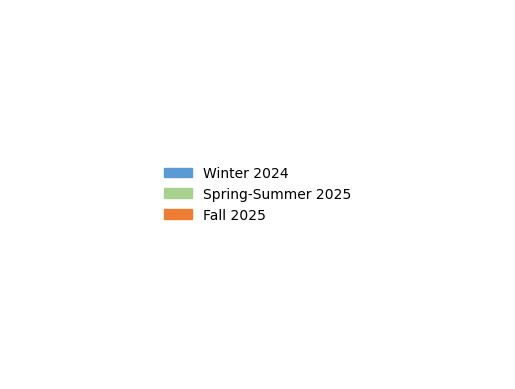

In [7]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Define colors
colors = {
    "Winter 2024": "#5B9BD5",
    "Spring-Summer 2025": "#A9D18E",
    "Fall 2025": "#ED7D31"
}

# Create square patches
legend_patches = [
    mpatches.Patch(color=color, label=label)
    for label, color in colors.items()
]

# Dummy plot (optional, just to show legend)
fig, ax = plt.subplots()
ax.plot([])  # no data

# Add legend
ax.legend(handles=legend_patches, loc='center', frameon=False)

# Remove axes for clean legend-only figure
ax.axis('off')

plt.show()

In [8]:
data[data["Dust sampler_ID"].isin(["SA-REF-1", "SA-REF-2", "SA-REF-3"])].loc[:,['Season','Transect','distance','[Li] (ppb)','Dust sampler_ID']]

,Season,Transect,distance,[Li] (ppb),Dust sampler_ID
22,Winter 2024,Ref_background,0,10.050725,SA-REF-1
23,Winter 2024,Ref_background,0,14.774101,SA-REF-2
24,Winter 2024,Ref_background,0,79.879907,SA-REF-3
50,Spring-Summer 2025,Ref_background,0,-36.138255,SA-REF-1
51,Spring-Summer 2025,Ref_background,0,-32.799375,SA-REF-2
52,Spring-Summer 2025,Ref_background,0,64.748501,SA-REF-3
79,Fall 2025,Ref_background,0,4.226285,SA-REF-1
80,Fall 2025,Ref_background,0,-9.577349,SA-REF-2
81,Fall 2025,Ref_background,0,22.066714,SA-REF-3


In [9]:
data['[Li] (ppb)'].quantile(0.95)

np.float64(2151.299868478268)

In [10]:
def plot_bar(dataframe, tnumber, y_col, season_color=None, fig_size=(10, 5), show_legend=True, get_fig=False,flip=False,noaxis=False,bar_width = 16):

	# --- Reference lines ---
	ref_df = dataframe[dataframe["Dust sampler_ID"].isin(["SA-REF-1", "SA-REF-2", "SA-REF-3"])].copy()
	ref_df[y_col] = ref_df[y_col].clip(lower=0)
	ref_means = ref_df.groupby("Season")[y_col].mean()

	# --- Filter transect ---
	if type(tnumber) == str:
		df = dataframe[dataframe["Transect"] == tnumber].copy()
	elif  type(tnumber) == list:
		df = data.query('Transect in @tnumber').copy()
	else:
		raise ValueError('Unknwon tnumber type')
	# Only seasons present in this transect, in dict order
	seasons = [s for s in SEASON_COLORS.keys() if s in df["Season"].values]
	distances = sorted(df["distance"].unique())
	n_seasons = len(seasons)

	# Bar width and offsets
	overlap = 0.10
	effective_width = bar_width * (1 - overlap)
	offsets = np.linspace(0, bar_width * (n_seasons - 1), n_seasons)
	offsets -= offsets.mean()

	# Colors
	if season_color is not None:
		colors = [SEASON_COLORS.get(s, "#333333") for s in seasons]
	else:
		colors = plt.cm.tab10(np.linspace(0, 1, n_seasons))

	fig, ax = plt.subplots(figsize=fig_size)

	# --- Bars --- 
	ymax = dataframe[y_col].quantile(0.95)
	for i, (season, color) in enumerate(zip(seasons, colors)):
		subset = df[df["Season"] == season]
		grouped = subset.groupby("distance")[y_col].apply(lambda x: x.clip(lower=0).mean()) 

		ax.bar(
			grouped.index + offsets[i],
			grouped.values,
			width=effective_width,
			label=season,
			color=color,
			edgecolor="white",
			linewidth=0.5,
		)


	# --- Reference lines ---
	for i, season in enumerate(seasons):
		if season not in ref_means.index:
			continue

		mean_val = ref_means[season]
		x_center = offsets[i]  # distance=0 bar center for this season
		# print(mean_val)
		
		ax.hlines(
			y=mean_val,
			xmin=offsets[0] - effective_width,
			xmax= max(distances) + effective_width*2 ,   #x_center + effective_width / 1.5,
			colors=SEASON_COLORS.get(season, "red"),
			linewidths=2,
			linestyles="--",
			label=f"{season} ref. mean",
		)

	if noaxis:
		pass
	else:
		ax.set_xlabel(f"Transect {tnumber} - Distance (m)", fontsize=13)
	
	ax.set_ylabel(f"{y_col}", fontsize=13)
	
	ax.set_ylim(bottom=0,top=ymax)
	# ax.set_xlim(offsets[0] - effective_width,1000)
	ax.set_xticks(distances)
	ax.set_xticklabels(distances) 
	if flip:
		ax.invert_xaxis() 
		ax.yaxis.set_ticks_position('right')
		ax.spines["left"].set_visible(False)
		ax.spines["right"].set_visible(True)
	else:
		ax.spines["right"].set_visible(False)

	if show_legend:
		ax.legend(title="Season", bbox_to_anchor=(1.01, 1), loc="upper left")

	# ax.axhline(0, color="black", linewidth=0.5, linestyle="--")
	ax.spines["top"].set_visible(False)






	plt.tight_layout()
	fig.patch.set_alpha(0)
	ax.patch.set_alpha(0)

	if get_fig:
		return fig
	else:
		plt.show()




In [19]:
def plot_bar_means(dataframe, tnumber, y_col, season_color=None, fig_size=(10, 5), show_legend=True, get_fig=False, flip=False, noaxis=False, bar_width=16):

    # --- Reference lines ---
    ref_df = dataframe[dataframe["Dust sampler_ID"].isin(["SA-REF-1", "SA-REF-2", "SA-REF-3"])].copy()
    ref_df[y_col] = ref_df[y_col].clip(lower=0)
    ref_means = ref_df.groupby("Season")[y_col].mean()

    # --- Filter transect ---
    if type(tnumber) == str:
        df = dataframe[dataframe["Transect"] == tnumber].copy()
    elif type(tnumber) == list:
        df = data.query('Transect in @tnumber').copy()
    else:
        raise ValueError('Unknown tnumber type')

    seasons = [s for s in SEASON_COLORS.keys() if s in df["Season"].values]
    distances = sorted(df["distance"].unique())

    fig, ax = plt.subplots(figsize=fig_size)

    # --- Compute average across all seasons per distance ---
    df_clipped = df.copy()
    df_clipped[y_col] = df_clipped[y_col].clip(lower=0)
    avg_across_seasons = df_clipped.groupby("distance")[y_col].mean()

    ymax = dataframe[y_col].quantile(0.95)

    # --- Single set of black bars ---
    ax.bar(
        avg_across_seasons.index,
        avg_across_seasons.values,
        width=bar_width * 0.9,
        label="Mean (all seasons)",
        color="grey",
        edgecolor="white",
        linewidth=0.5,
    )

    # --- Reference lines (overall mean across seasons) ---
    overall_ref_mean = ref_means.mean()
    ax.hlines(
        y=overall_ref_mean,
        xmin=min(distances) - bar_width,
        xmax=max(distances) + bar_width,
        colors="black",
        linewidths=2,
        linestyles="--",
        label="Ref. mean (all seasons)",
    )

    if noaxis:
        pass
    else:
        ax.set_xlabel(f"Transect {tnumber} - Distance (m)", fontsize=13)

    ax.set_ylabel(f"{y_col}", fontsize=13)
    ax.set_ylim(bottom=0, top=ymax)
    ax.set_xticks(distances)
    ax.set_xticklabels(distances)

    if flip:
        ax.invert_xaxis()
        ax.yaxis.set_ticks_position('right')
        ax.spines["left"].set_visible(False)
        ax.spines["right"].set_visible(True)
    else:
        ax.spines["right"].set_visible(False)

    if show_legend:
        ax.legend(title="Season", bbox_to_anchor=(1.01, 1), loc="upper left")

    ax.spines["top"].set_visible(False)

    plt.tight_layout()
    fig.patch.set_alpha(0)
    ax.patch.set_alpha(0)

    if get_fig:
        return fig
    else:
        plt.show()

In [20]:
flips = ['1', '3','6']


In [21]:
data['Transect'].unique()

array(['1', '2', '3', '4', '5', '6', 'Ref_background', 'Ref_internal'],
      dtype=object)

In [22]:
data.columns

Index(['Sample ID', 'Season', 'Dust sampler_ID', 'Transect', 'LatDecimal',
       'LonDecimal', 'LatDMS', 'LonDMS', 'distance', 'check ID',
       'Change in mass (mg)', '(mg/dm2/day)', '[Al] (ppm)', '[As] (ppm)',
       '[Ba] (ppm)', '[Bi] (ppm)', '[Ca] (ppm)', '[Cd] (ppm)', '[Co] (ppm)',
       '[Cr] (ppm)', '[Cu] (ppm)', '[Fe] (ppm)', '[K] (ppm)', '[Li] (ppm)',
       '[Mg] (ppm)', '[Mn] (ppm)', '[Mo] (ppm)', '[Na] (ppm)', '[Ni] (ppm)',
       '[P] (ppm)', '[Pb] (ppm)', '[S (ICP)] (ppm)', '[Sb] (ppm)',
       '[Se] (ppm)', '[Si] (ppm)', '[Sr] (ppm)', '[Ti] (ppm)', '[V] (ppm)',
       '[Zn] (ppm)', '[Zr] (ppm)', '[As] (ppb)', '[Ba] (ppb)', '[Be] (ppb)',
       '[Ce] (ppb)', '[Co] (ppb)', '[Cr] (ppb)', '[Cu] (ppb)', '[Li] (ppb)',
       '[Nb] (ppb)', '[Pb] (ppb)', '[Rb] (ppb)', '[Tl] (ppb)', '[V] (ppb)'],
      dtype='object')

In [44]:
data[['[As] (ppb)','[Be] (ppb)', '[Li] (ppb)','[Pb] (ppb)' ]].describe()

,[As] (ppb),[Be] (ppb),[Li] (ppb),[Pb] (ppb)
count,84.000000,84.000000,84.000000,84.000000
mean,0.225181,15.412666,475.004716,31.758067
std,0.989657,40.671698,1052.129618,166.787633
min,-0.477714,-0.502282,-36.138255,-4.301003
25%,-0.230720,0.899182,41.023614,0.468500
50%,0.013449,3.602731,122.207006,2.294156
75%,0.339047,11.500758,434.858645,6.771921
max,6.537778,327.910226,7830.069826,1382.226589


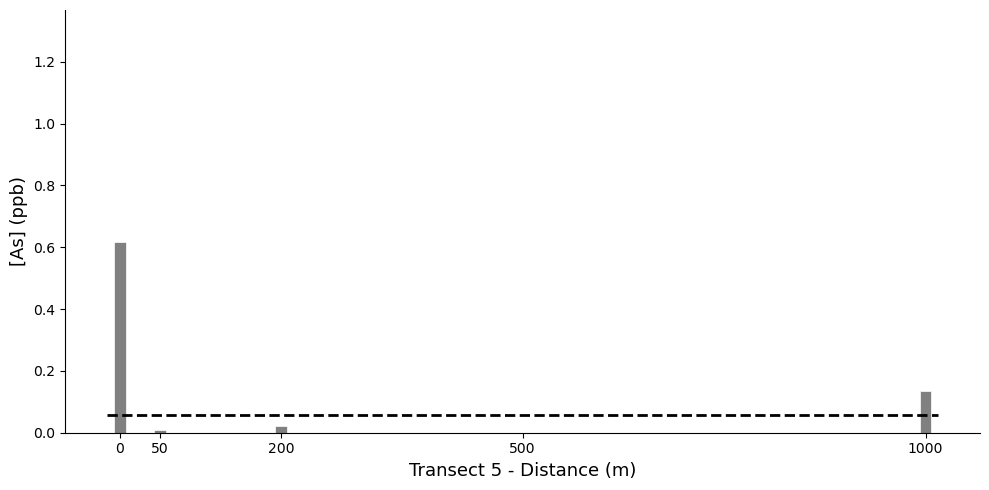

In [42]:


tnumber = '5'
flip = tnumber in flips
y_col = '[As] (ppb)'
fig = plot_bar_means(data, tnumber, y_col, season_color=None, fig_size=(10, 5), show_legend=False, get_fig=False, flip=flip, noaxis=False, bar_width=16)

# plt.savefig(os.path.join(save_path,f'transect{tnumber}_elem-{y_col}.svg'), format='svg', dpi=200, transparent=True, bbox_inches="tight")
plt.show()

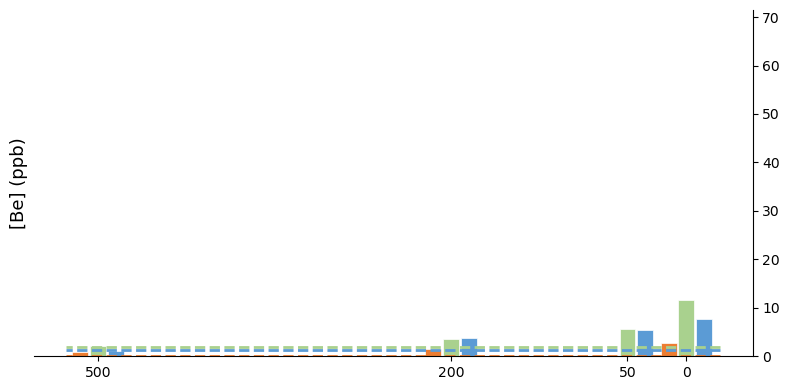

In [ ]:
tnumber = '1'
flip = tnumber in flips
y_col = '[Be] (ppb)'
fig = plot_bar(data,tnumber, y_col, season_color=SEASON_COLORS,fig_size=(8, 4), show_legend=False,get_fig=True, flip=flip, noaxis=True,bar_width = 15)

# plt.savefig(os.path.join(save_path,f'transect{tnumber}_elem-{y_col}.svg'), format='svg', dpi=200, transparent=True, bbox_inches="tight")
plt.show()

In [51]:
data.columns

Index(['Sample ID', 'Season', 'Dust sampler_ID', 'Transect', 'LatDecimal',
       'LonDecimal', 'LatDMS', 'LonDMS', 'distance', 'check ID',
       'Change in mass (mg)', '(mg/dm2/day)', '[Al] (ppm)', '[As] (ppm)',
       '[Ba] (ppm)', '[Bi] (ppm)', '[Ca] (ppm)', '[Cd] (ppm)', '[Co] (ppm)',
       '[Cr] (ppm)', '[Cu] (ppm)', '[Fe] (ppm)', '[K] (ppm)', '[Li] (ppm)',
       '[Mg] (ppm)', '[Mn] (ppm)', '[Mo] (ppm)', '[Na] (ppm)', '[Ni] (ppm)',
       '[P] (ppm)', '[Pb] (ppm)', '[S (ICP)] (ppm)', '[Sb] (ppm)',
       '[Se] (ppm)', '[Si] (ppm)', '[Sr] (ppm)', '[Ti] (ppm)', '[V] (ppm)',
       '[Zn] (ppm)', '[Zr] (ppm)', '[As] (ppb)', '[Ba] (ppb)', '[Be] (ppb)',
       '[Ce] (ppb)', '[Co] (ppb)', '[Cr] (ppb)', '[Cu] (ppb)', '[Li] (ppb)',
       '[Nb] (ppb)', '[Pb] (ppb)', '[Rb] (ppb)', '[Tl] (ppb)', '[V] (ppb)'],
      dtype='object')

In [52]:
ppb_cols = [c for c in data.columns if c.endswith('(ppb)')]
ppb_cols

['[As] (ppb)',
 '[Ba] (ppb)',
 '[Be] (ppb)',
 '[Ce] (ppb)',
 '[Co] (ppb)',
 '[Cr] (ppb)',
 '[Cu] (ppb)',
 '[Li] (ppb)',
 '[Nb] (ppb)',
 '[Pb] (ppb)',
 '[Rb] (ppb)',
 '[Tl] (ppb)',
 '[V] (ppb)']

In [53]:
data[data['Transect']=='Ref_background'].loc[:,ppb_cols].describe()

,[As] (ppb),[Ba] (ppb),[Be] (ppb),[Ce] (ppb),[Co] (ppb),[Cr] (ppb),[Cu] (ppb),[Li] (ppb),[Nb] (ppb),[Pb] (ppb),[Rb] (ppb),[Tl] (ppb),[V] (ppb)
count,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000
mean,-0.153520,12.420640,0.912496,0.611187,-0.327178,8.773587,1.033976,13.025695,0.216915,-0.796182,27.161748,0.057759,2.805759
std,0.260624,11.508577,2.239224,0.761389,1.285297,10.044516,5.966179,39.280625,0.572410,1.889497,37.122885,0.296737,2.778556
min,-0.447719,-0.406485,-0.468142,-0.046055,-3.104965,1.541798,-4.104943,-36.138255,-0.108823,-3.862516,1.331827,-0.129596,-0.012278
25%,-0.383694,-0.222758,-0.454052,0.106474,-0.947722,3.585487,-3.038364,-9.577349,-0.067501,-2.181448,7.351201,-0.114651,1.117064
50%,-0.216188,13.588725,-0.001985,0.225534,-0.245656,4.042808,-0.441646,10.050725,0.012540,-0.373109,8.652788,-0.102381,1.679573
75%,0.130753,22.830290,0.075529,1.011225,0.746879,9.051924,2.329911,22.066714,0.227968,0.744740,30.069312,0.072051,3.562056
max,0.244099,28.236841,5.490369,2.324159,0.845864,32.539319,15.388032,79.879907,1.702651,1.358296,105.594167,0.719946,9.152582


In [54]:
data[data['Transect']=='1'].loc[:,ppb_cols].describe()

,[As] (ppb),[Ba] (ppb),[Be] (ppb),[Ce] (ppb),[Co] (ppb),[Cr] (ppb),[Cu] (ppb),[Li] (ppb),[Nb] (ppb),[Pb] (ppb),[Rb] (ppb),[Tl] (ppb),[V] (ppb)
count,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000
mean,1.490440,223.043385,3.803730,19.933369,10.290624,94.950823,34.625441,173.287045,3.858403,58.284321,163.963509,1.073415,62.487151
std,2.080225,315.922882,3.371814,27.548165,14.619434,103.613822,44.898438,160.883470,5.535860,191.490087,131.853133,1.027788,82.809193
min,-0.275986,20.318367,-0.502282,2.055933,-0.010542,14.669735,-4.996508,41.894208,-0.228003,-2.226711,31.873042,0.112676,7.794004
25%,0.196216,65.460425,1.436337,5.351332,1.792745,28.939594,-0.709192,72.656031,-0.111118,0.643302,72.877350,0.364476,16.946103
50%,0.682541,91.665043,3.148775,8.153399,5.253283,66.486288,22.524902,115.426630,2.753715,1.902249,125.317578,0.721491,28.785999
75%,1.776890,236.831593,5.560687,24.671287,11.313769,97.475070,44.451696,230.831329,3.574107,6.273853,207.276942,1.356729,74.302903
max,6.537778,1157.776394,11.573121,100.782768,52.658473,383.408082,149.837324,592.869050,18.486121,666.217176,447.461889,3.241564,306.201848


In [55]:
data[data['Transect']=='6'].loc[:,ppb_cols].describe()

,[As] (ppb),[Ba] (ppb),[Be] (ppb),[Ce] (ppb),[Co] (ppb),[Cr] (ppb),[Cu] (ppb),[Li] (ppb),[Nb] (ppb),[Pb] (ppb),[Rb] (ppb),[Tl] (ppb),[V] (ppb)
count,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000
mean,0.033390,17.074921,0.737061,1.495431,-0.102214,16.260222,3.144042,22.733911,0.378413,1.238659,38.883521,0.073141,4.664402
std,0.301560,15.334585,1.006890,1.286990,2.036197,14.587134,8.558789,40.549357,0.695170,3.734921,32.944013,0.245601,4.016418
min,-0.477714,-0.472730,-0.468361,0.163902,-4.082126,1.851731,-4.604625,-26.804401,-0.126558,-4.301003,2.769245,-0.125204,0.428722
25%,-0.208166,0.034546,-0.002129,0.438609,-0.811481,5.990797,-3.586238,-9.240308,-0.079410,-0.852088,16.117497,-0.111161,1.730351
50%,0.022869,16.328499,0.671093,1.170376,-0.113777,13.241908,-0.351324,10.218682,-0.015450,0.995378,29.157294,-0.048459,3.535242
75%,0.339047,27.224139,1.090454,2.376206,1.482237,19.224627,9.100770,59.481437,0.883646,3.256384,57.742342,0.221487,6.752786
max,0.442119,43.614860,2.880009,4.307296,2.899996,52.978333,20.776682,96.858074,1.946373,8.094945,107.410692,0.647162,13.866567


In [56]:
data[data['Transect']=='2'].loc[:,ppb_cols].describe()

,[As] (ppb),[Ba] (ppb),[Be] (ppb),[Ce] (ppb),[Co] (ppb),[Cr] (ppb),[Cu] (ppb),[Li] (ppb),[Nb] (ppb),[Pb] (ppb),[Rb] (ppb),[Tl] (ppb),[V] (ppb)
count,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000
mean,0.175499,141.951918,10.393435,13.571090,16.229261,250.599008,58.474007,440.920858,8.142446,5.722365,454.619992,3.117082,61.472591
std,0.394539,141.862431,11.486910,14.653417,21.724803,286.139872,84.623821,444.578292,10.425634,7.642654,530.662638,3.658480,72.764455
min,-0.270715,7.418387,1.106960,1.091698,-1.643295,13.754568,-3.217184,38.411831,-0.051298,-2.549619,35.627211,0.091175,4.319439
25%,-0.207374,42.971076,2.466087,2.763351,1.260763,40.409394,8.248233,87.971194,0.725567,1.508265,86.074719,0.535789,10.963516
50%,0.148217,74.125633,4.600324,7.045223,5.796441,132.731027,36.741972,221.311111,3.332142,4.255543,235.267973,1.629364,32.451969
75%,0.326687,223.705290,19.046219,19.929781,22.775578,326.421057,50.930207,674.837484,11.910183,6.642717,546.812831,3.942990,75.182652
max,0.880208,437.616048,37.956021,46.704500,66.785153,919.333001,277.148603,1356.550026,35.603081,26.553747,1732.142402,11.938989,236.413092


In [57]:
data[data['Transect']=='5'].loc[:,ppb_cols].describe()

,[As] (ppb),[Ba] (ppb),[Be] (ppb),[Ce] (ppb),[Co] (ppb),[Cr] (ppb),[Cu] (ppb),[Li] (ppb),[Nb] (ppb),[Pb] (ppb),[Rb] (ppb),[Tl] (ppb),[V] (ppb)
count,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000
mean,-0.020557,113.455595,8.332555,10.969106,12.822350,172.598574,42.067257,338.233092,6.489164,4.249356,370.936406,2.636755,47.527452
std,0.487565,136.725519,10.783007,15.042948,20.216777,269.039533,75.736231,438.477272,9.471088,7.234270,510.188085,3.641284,70.601736
min,-0.417191,9.604446,-0.467353,0.386180,0.127964,7.155282,-3.596384,9.254208,-0.106069,-2.938757,18.053042,-0.003324,2.108162
25%,-0.318230,28.381770,2.630067,1.935157,1.743459,32.986578,-0.503162,78.026785,-0.000425,1.006032,92.571448,0.607156,8.676957
50%,-0.199021,59.209251,4.398248,5.709434,5.132935,71.849608,15.799809,174.304916,2.422368,2.637721,181.687328,1.240375,22.509959
75%,0.044302,136.283951,10.286861,12.725352,13.923531,168.697972,44.255689,419.451180,7.202160,5.314243,402.596997,2.962655,49.008092
max,1.468275,510.312570,40.303499,57.859993,78.944227,1061.100666,291.980602,1623.460066,34.247945,26.906778,1991.218768,14.024902,274.430444


In [58]:
data[data['Transect']=='3'].loc[:,ppb_cols].describe()

,[As] (ppb),[Ba] (ppb),[Be] (ppb),[Ce] (ppb),[Co] (ppb),[Cr] (ppb),[Cu] (ppb),[Li] (ppb),[Nb] (ppb),[Pb] (ppb),[Rb] (ppb),[Tl] (ppb),[V] (ppb)
count,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000
mean,-0.180515,42.502504,5.944248,2.938184,0.406903,35.166565,6.758569,179.677194,3.268011,2.852342,190.501591,1.403465,10.105339
std,0.218648,32.350276,4.384426,2.408919,3.032798,21.800460,7.392136,124.423372,2.808858,3.496477,122.153714,0.955046,7.859840
min,-0.412547,-0.273904,-0.457975,0.177943,-4.120735,5.396049,-3.489853,10.238166,-0.073329,-1.832651,19.925169,0.014005,0.923558
25%,-0.350762,23.584205,3.635845,0.910658,-0.646487,14.154564,-0.367924,63.466550,0.384575,0.520390,77.338141,0.597476,2.888945
50%,-0.228372,39.430242,5.683003,2.400888,-0.180661,44.066479,9.727972,201.880932,3.609224,2.111918,228.890476,1.769739,8.168489
75%,-0.045986,64.917057,9.709707,4.646892,1.755393,50.609069,11.278842,270.225045,5.387074,4.430263,291.321051,2.144781,17.041090
max,0.241539,92.169368,12.012229,6.862893,6.274302,64.818706,18.869565,369.807184,7.065298,10.096072,346.407926,2.535157,20.642981


In [59]:
data[data['Transect']=='4'].loc[:,ppb_cols].describe()

,[As] (ppb),[Ba] (ppb),[Be] (ppb),[Ce] (ppb),[Co] (ppb),[Cr] (ppb),[Cu] (ppb),[Li] (ppb),[Nb] (ppb),[Pb] (ppb),[Rb] (ppb),[Tl] (ppb),[V] (ppb)
count,8.000000,8.000000,8.000000,8.000000,8.000000,8.000000,8.000000,8.000000,8.000000,8.000000,8.000000,8.000000,8.000000
mean,-0.043945,127.292814,29.114591,9.768040,5.271407,102.405321,17.480573,812.264320,19.401255,21.920789,854.198527,6.557613,30.529171
std,0.305051,114.151258,23.205478,8.208917,5.848835,66.862106,15.260693,680.853750,18.509186,43.061651,617.359617,4.729053,22.633686
min,-0.442694,23.864093,0.195571,2.615263,-1.038629,25.185861,-0.685758,146.681204,-0.081896,1.147111,157.813709,1.018544,8.183139
25%,-0.225362,65.822534,17.599289,4.823097,0.975990,65.309490,8.499787,432.175978,10.589720,3.683425,530.742992,4.184283,15.715609
50%,-0.140799,75.495568,21.650700,5.974016,3.178889,71.337166,16.113315,547.729638,14.068283,7.960646,628.541187,4.831388,21.423009
75%,0.151612,156.297515,34.413868,13.002543,9.636048,142.227953,25.162080,978.575051,21.324669,10.947831,1101.896997,8.413345,41.880166
max,0.516670,375.403681,75.318848,27.414980,15.524987,226.609315,44.494752,2244.448069,60.450828,127.912697,2108.066408,16.225570,76.421935


In [60]:
data[data['Transect']=='Ref_internal'].loc[:,ppb_cols].describe()

,[As] (ppb),[Ba] (ppb),[Be] (ppb),[Ce] (ppb),[Co] (ppb),[Cr] (ppb),[Cu] (ppb),[Li] (ppb),[Nb] (ppb),[Pb] (ppb),[Rb] (ppb),[Tl] (ppb),[V] (ppb)
count,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000
mean,0.394998,429.323034,114.982208,38.061374,31.124500,425.686064,125.378405,3128.580036,98.723795,270.711504,4179.877833,31.604532,131.910972
std,0.591455,319.692372,110.515371,28.120050,23.968335,331.661070,124.953240,2589.230762,94.138696,545.992113,4091.527869,31.176700,97.496267
min,-0.212847,92.214671,24.035750,8.489800,5.399281,80.963150,19.244988,600.528396,11.669676,10.947976,500.923228,3.671104,26.797580
25%,-0.014281,216.362628,47.811873,19.119622,15.430218,205.086565,46.856572,1552.330036,35.433206,25.031479,1536.117844,11.461765,67.971414
50%,0.259471,314.720349,94.494140,28.770137,24.631599,322.279302,96.576169,2548.324132,71.076142,43.127758,2987.669190,21.657210,104.772755
75%,0.653177,699.604667,111.154441,58.561265,43.919948,620.261732,134.600974,3655.007325,130.454299,105.161609,5176.908377,40.378909,187.764773
max,1.385010,842.806677,327.910226,77.943745,69.372029,942.983101,362.313822,7830.069826,264.721563,1382.226589,11644.083222,87.958907,283.989662


In [66]:
columns_interest = ['[Pb] (ppb)','[Co] (ppb)',	'[Cr] (ppb)','[Li] (ppb)','[Rb] (ppb)','[Nb] (ppb)','[As] (ppb)' ,'[Be] (ppb)', '[Cu] (ppb)', ]

In [62]:
save_path

'c:\\Users\\bruno\\OneDrive - McGill University\\PhD_Research\\NRCan Data\\ICP-MS\\May25_Aug25_Nov25\\imgs'

C:\Users\bruno\AppData\Local\Temp\ipykernel_5720\2517368876.py:32: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(figsize=fig_size)


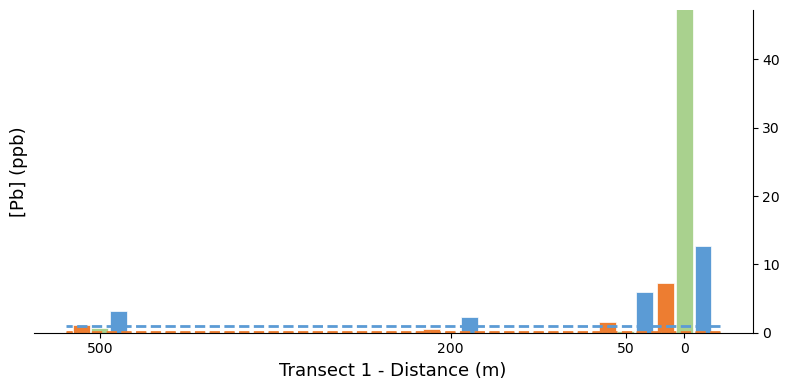

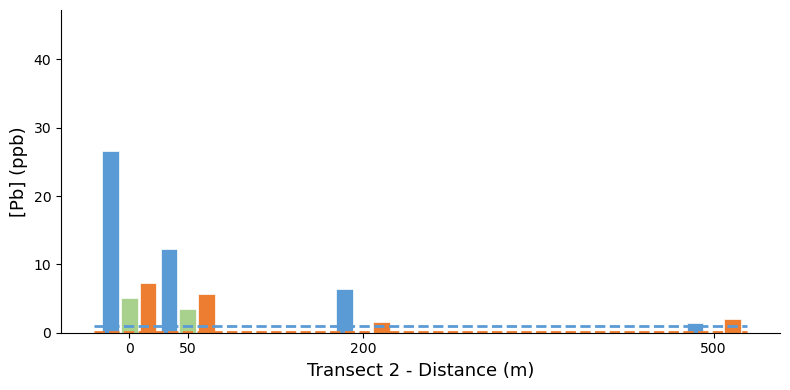

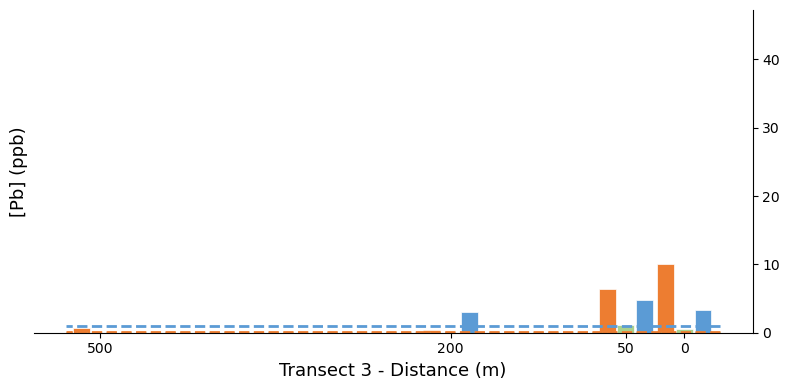

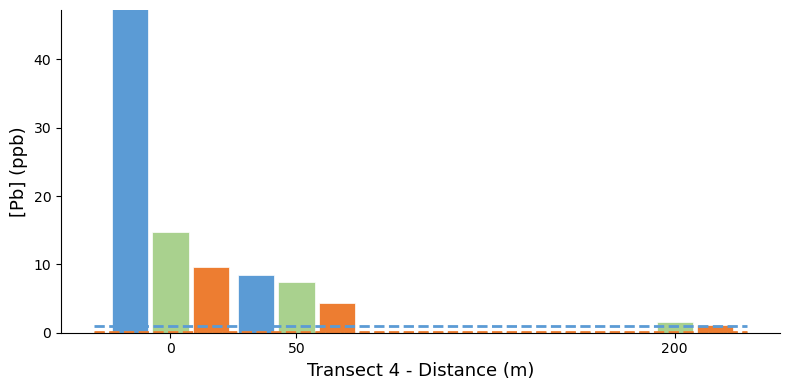

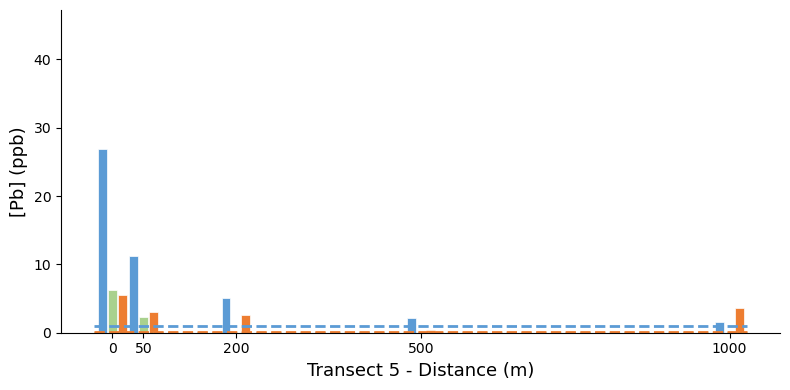

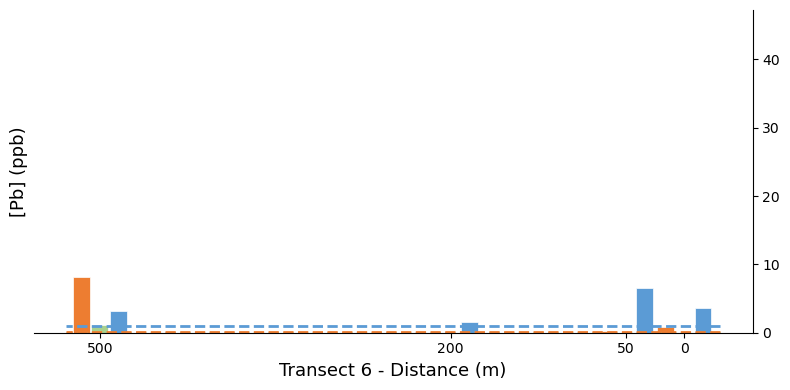

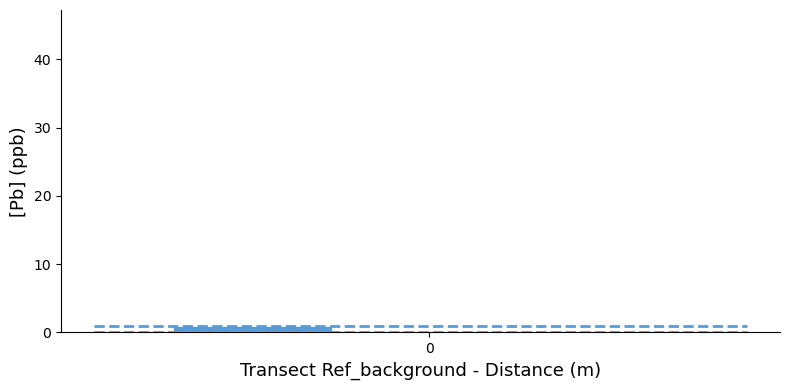

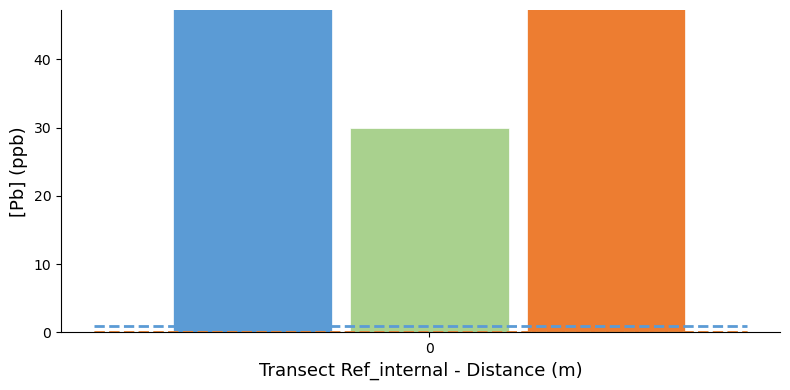

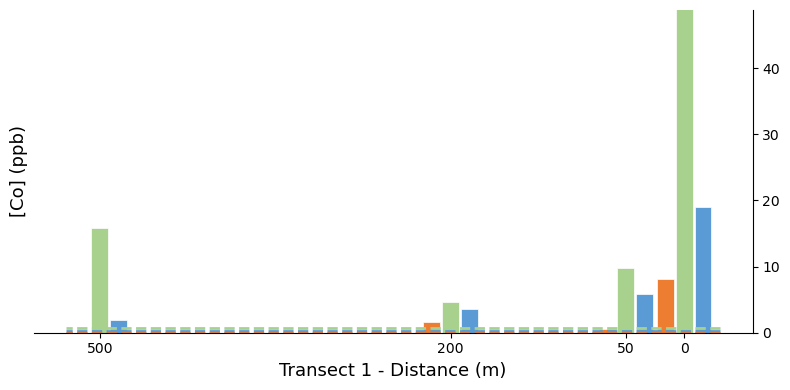

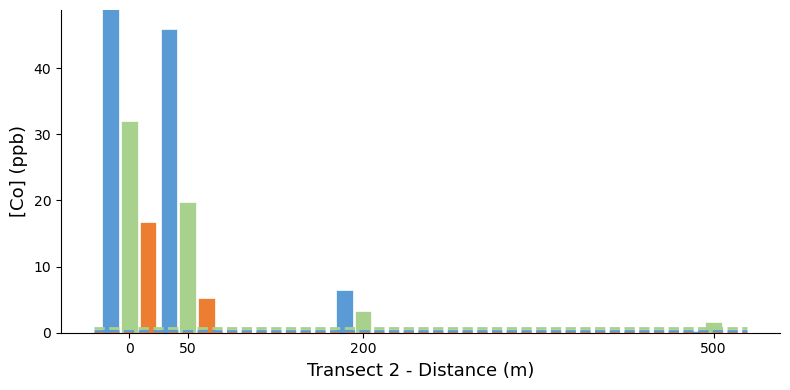

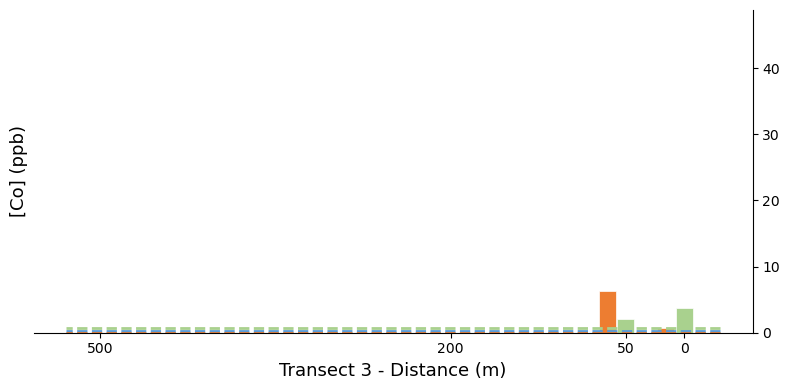

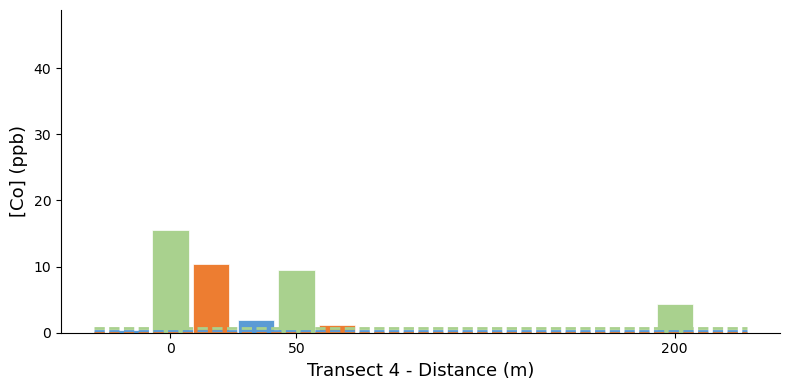

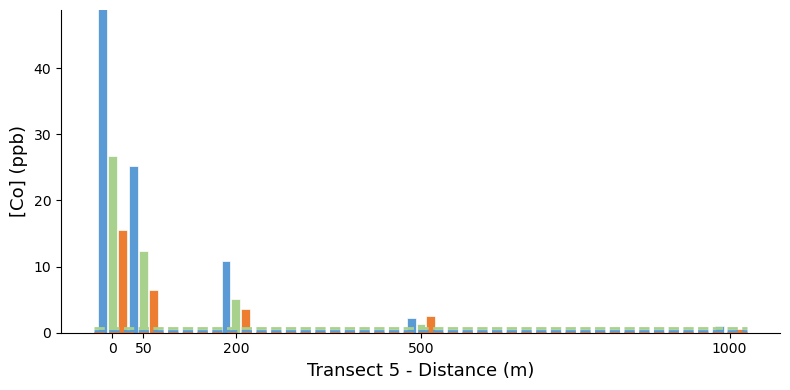

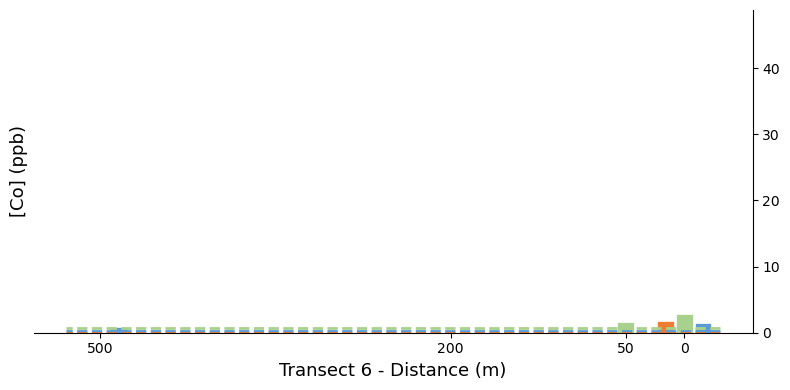

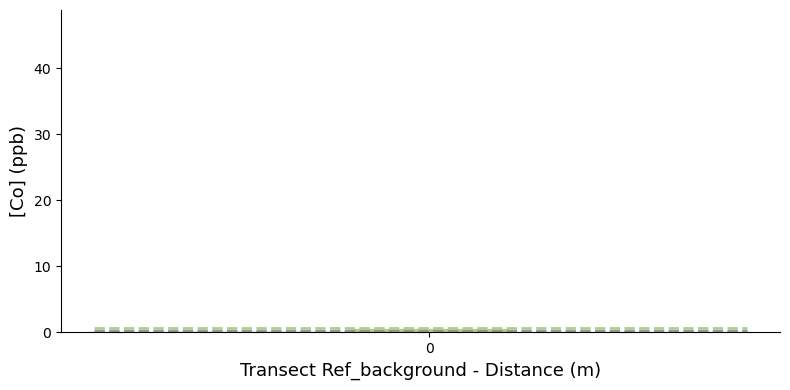

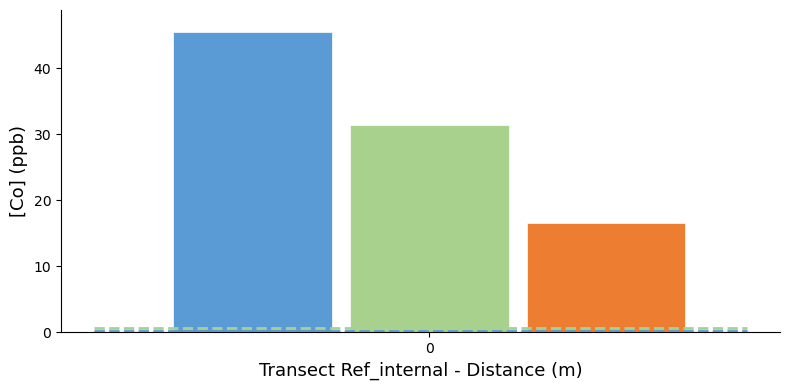

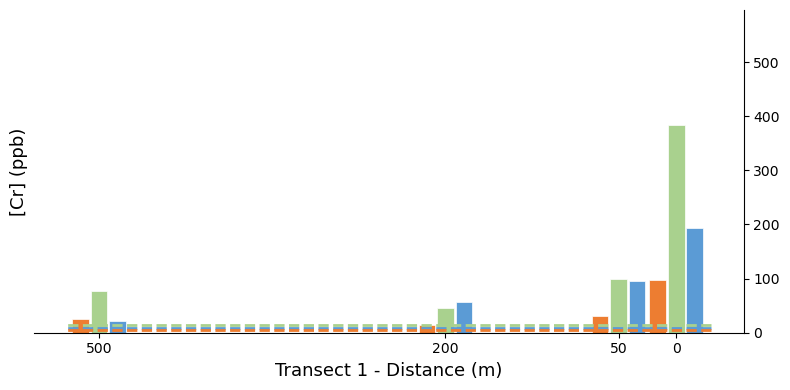

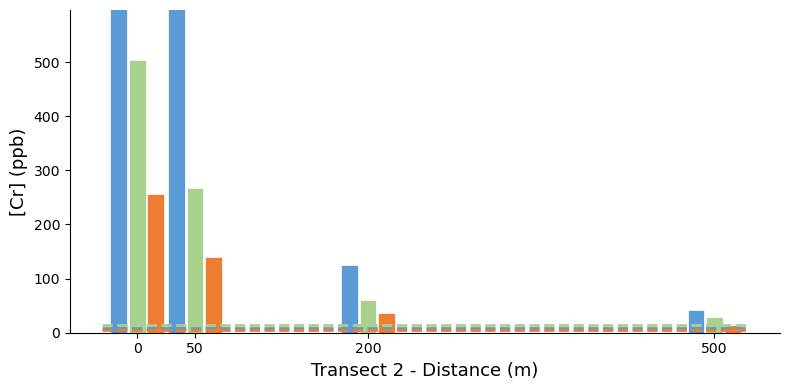

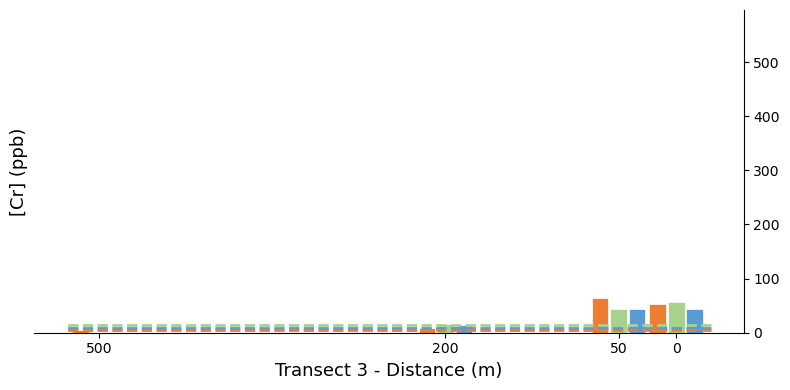

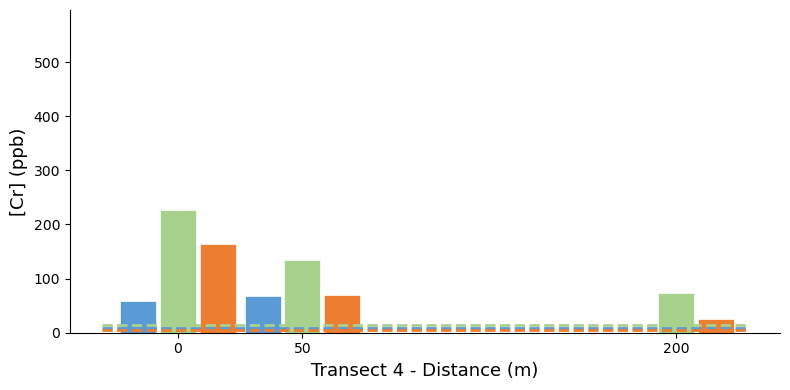

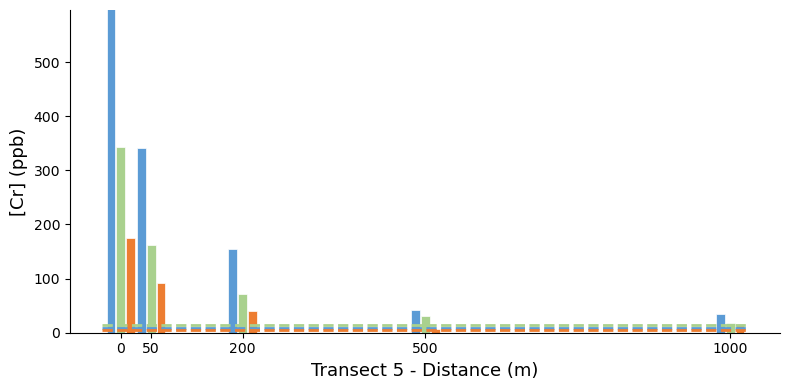

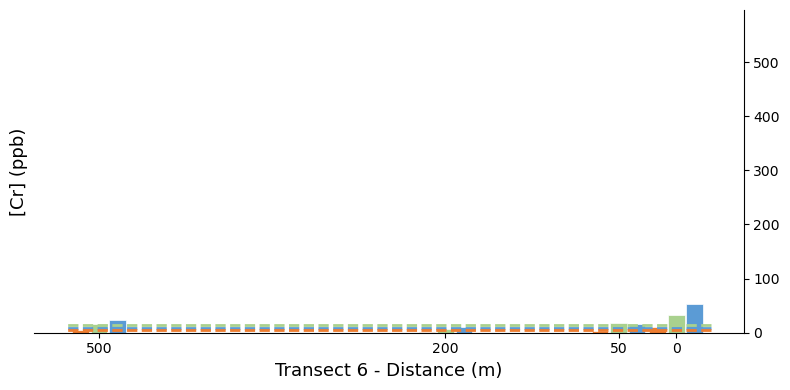

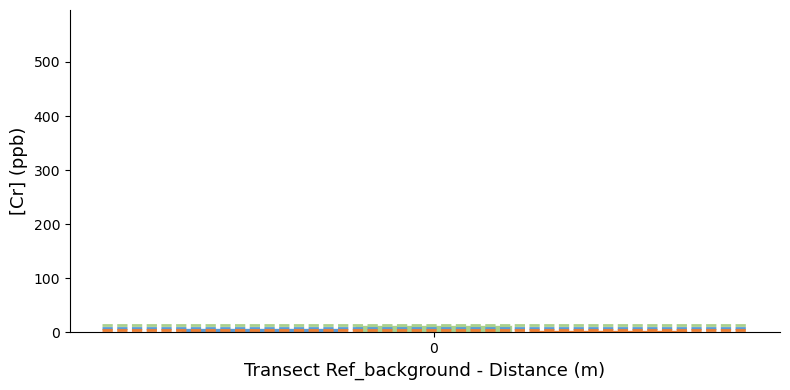

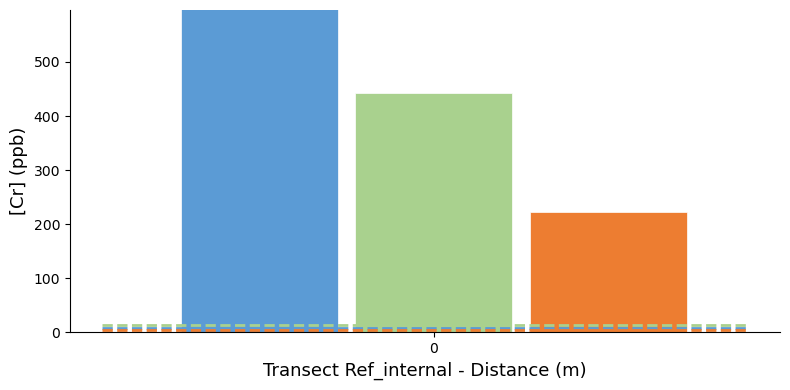

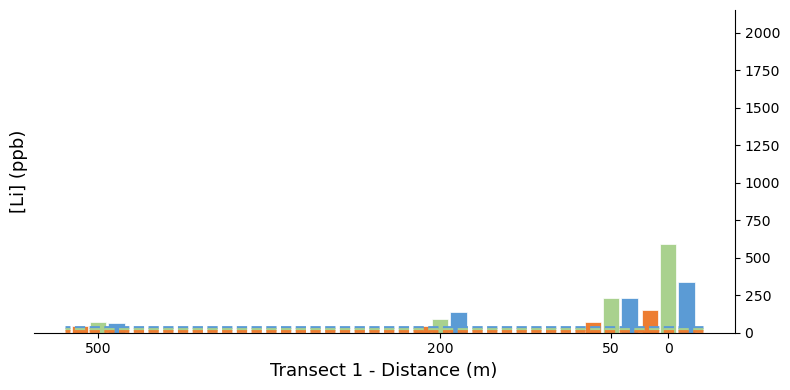

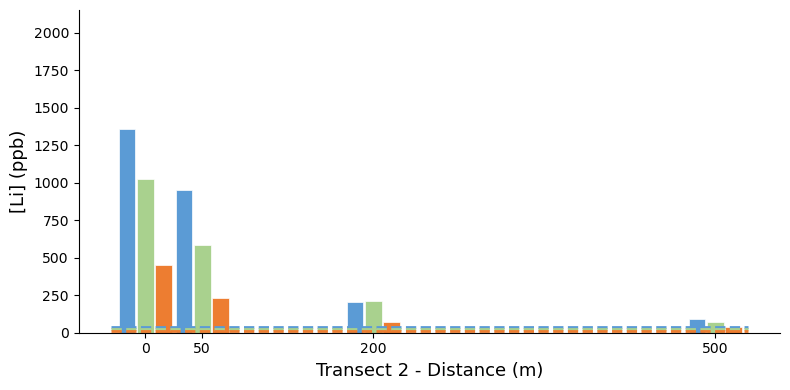

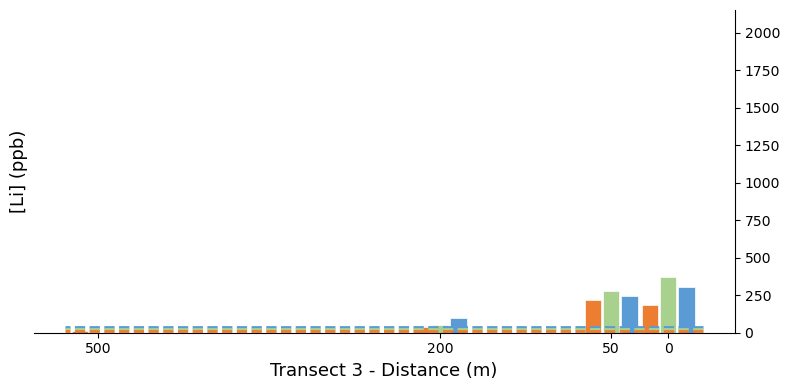

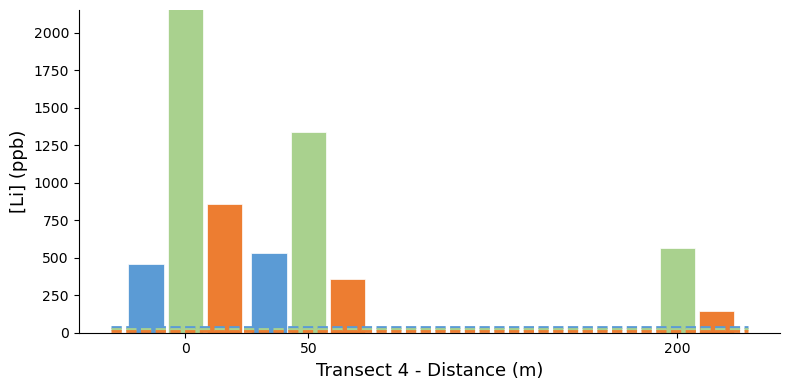

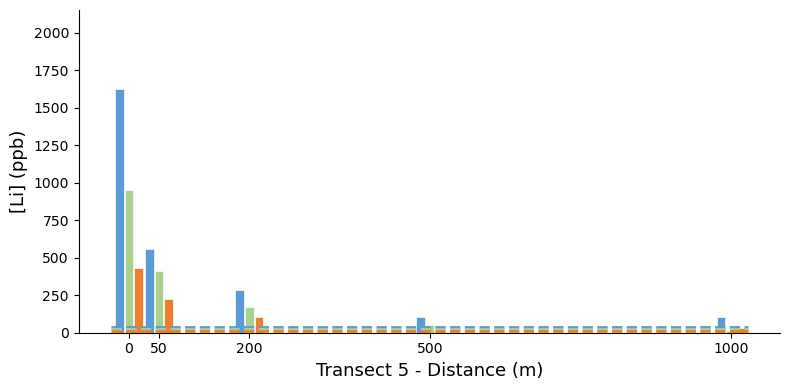

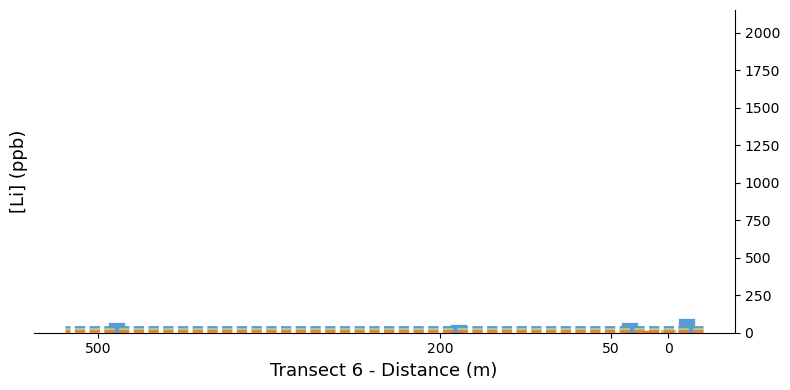

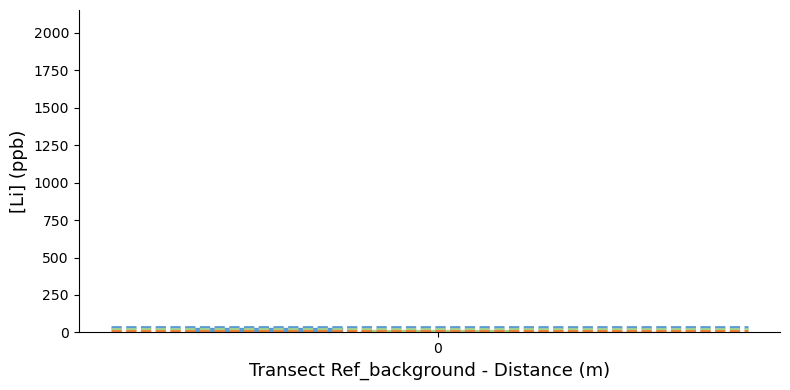

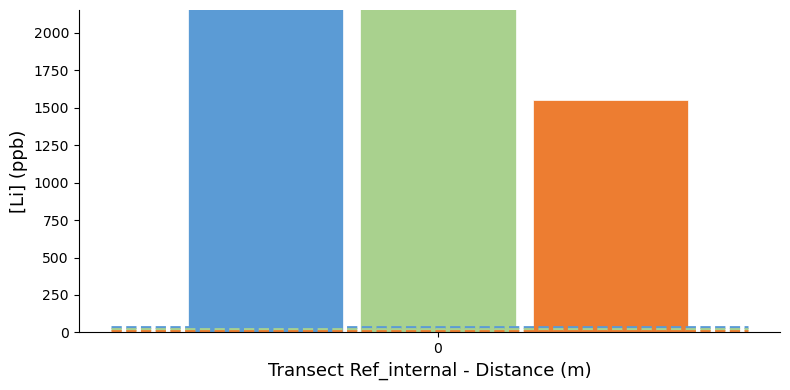

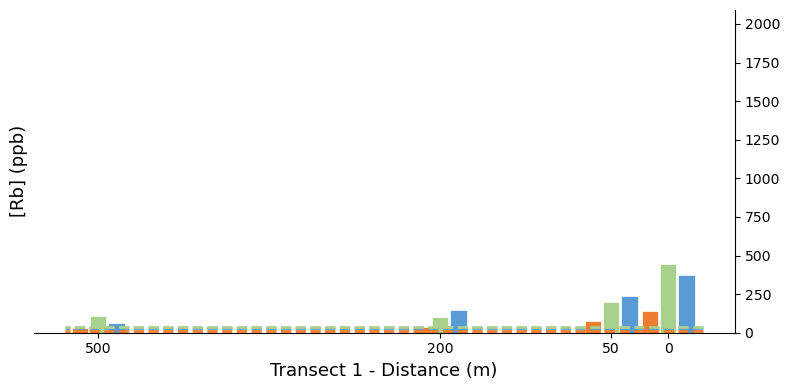

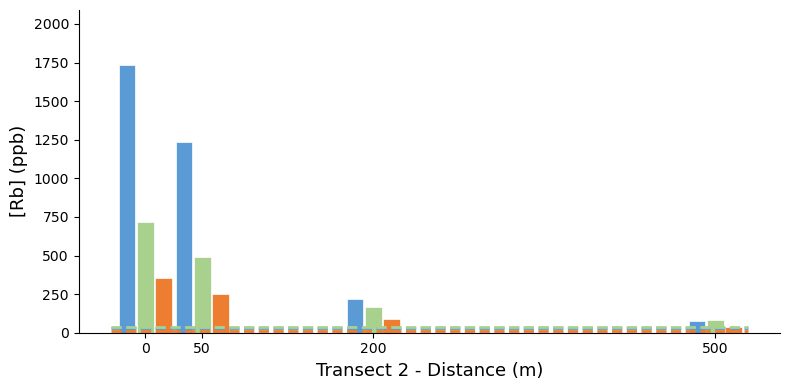

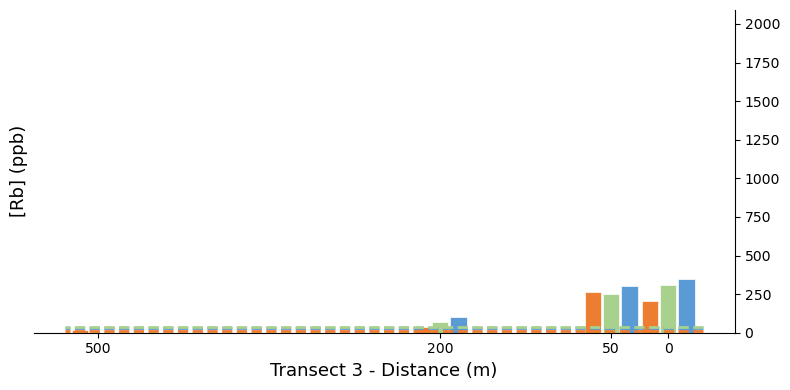

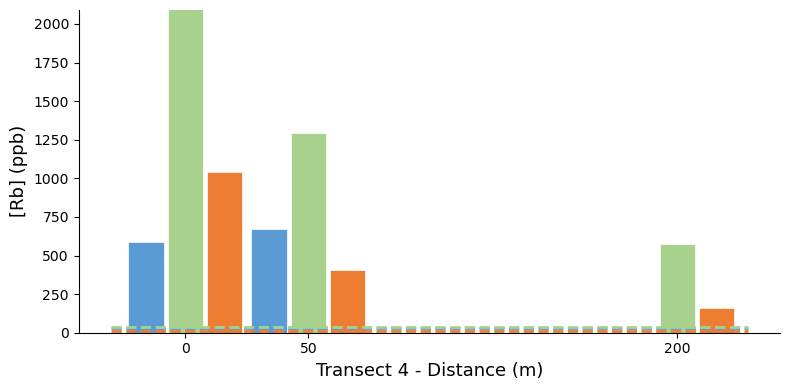

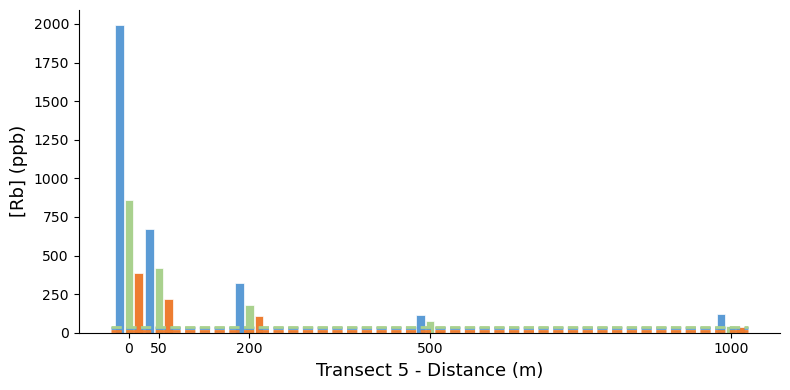

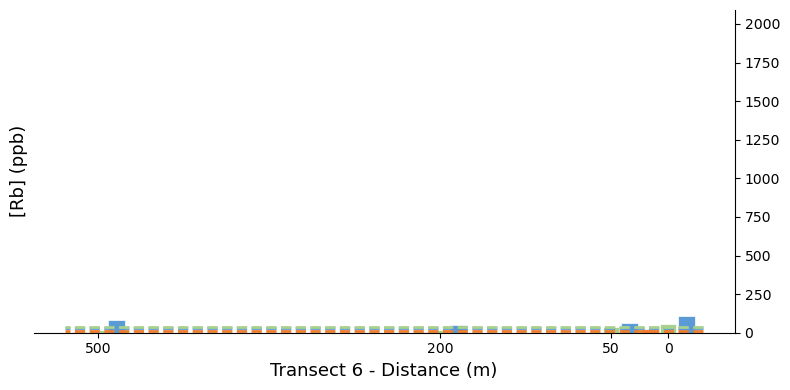

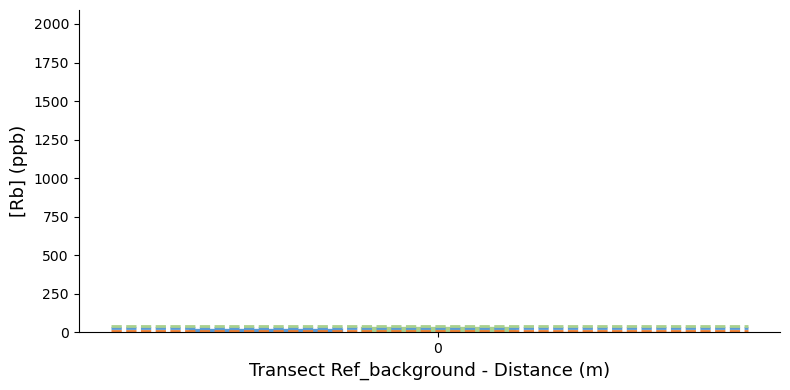

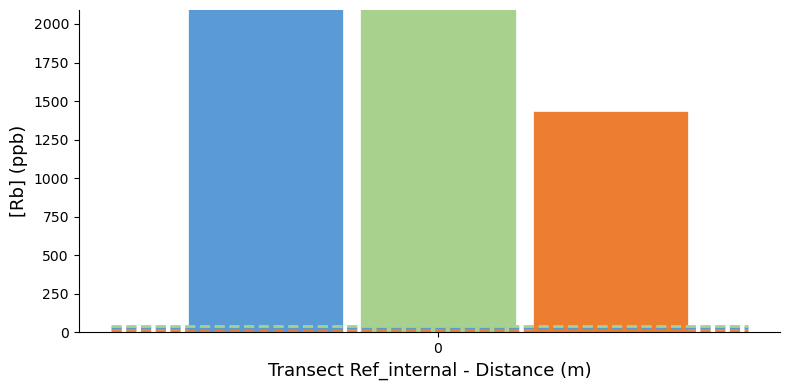

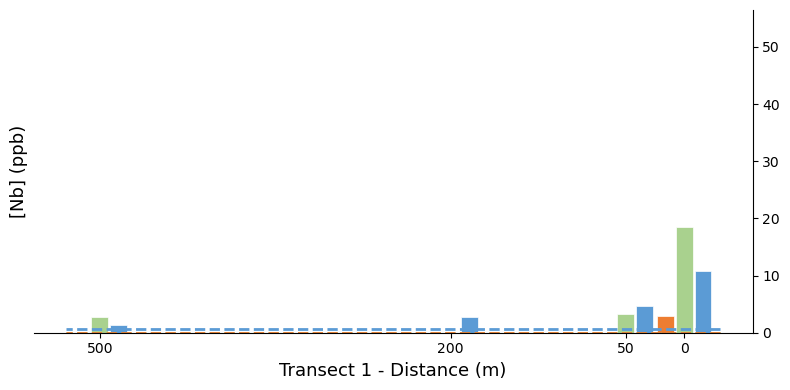

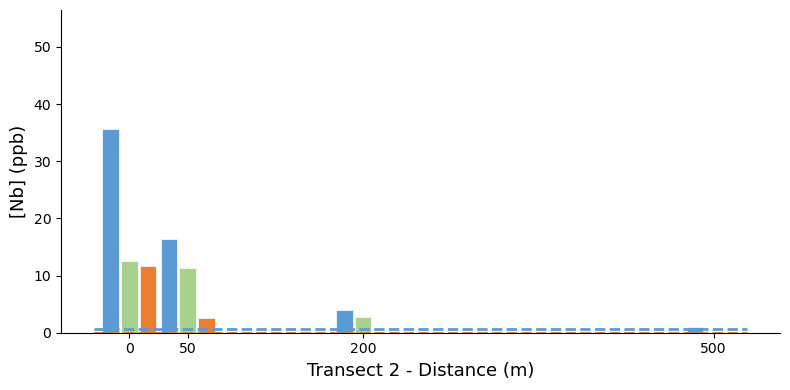

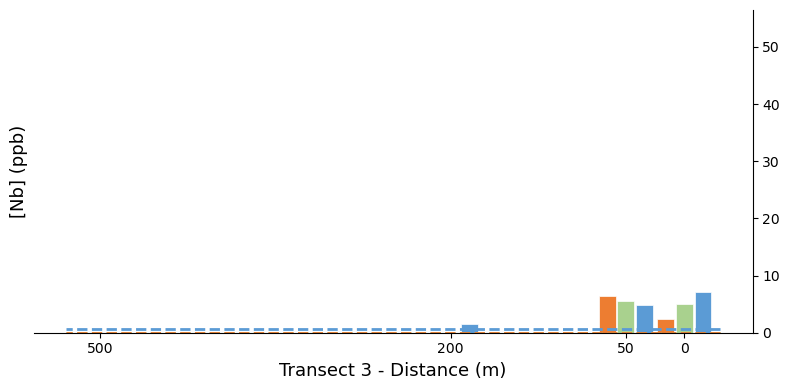

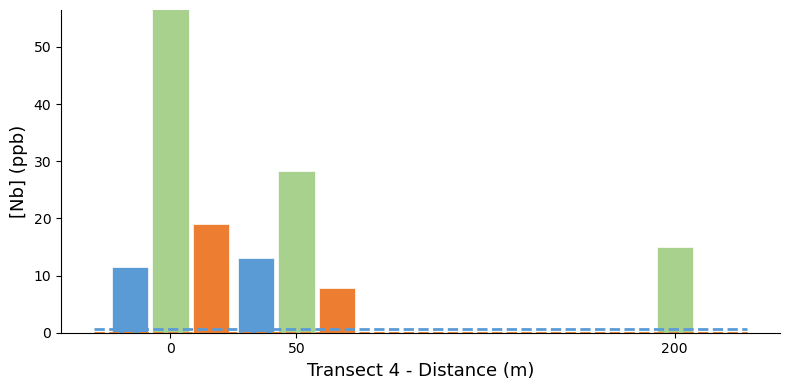

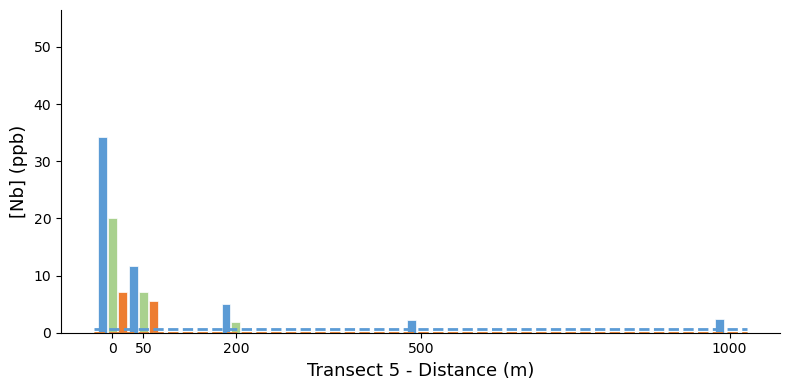

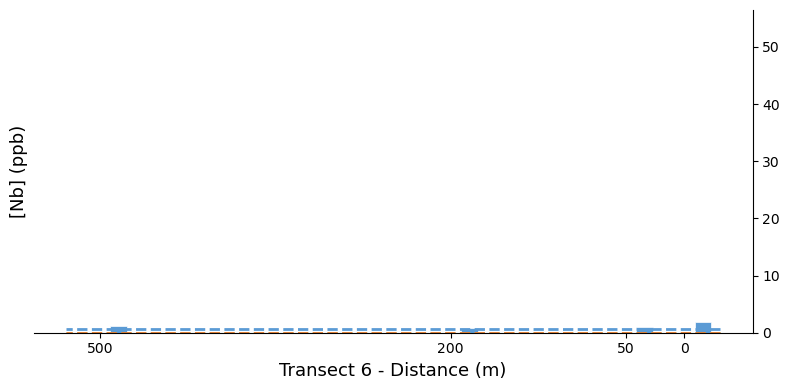

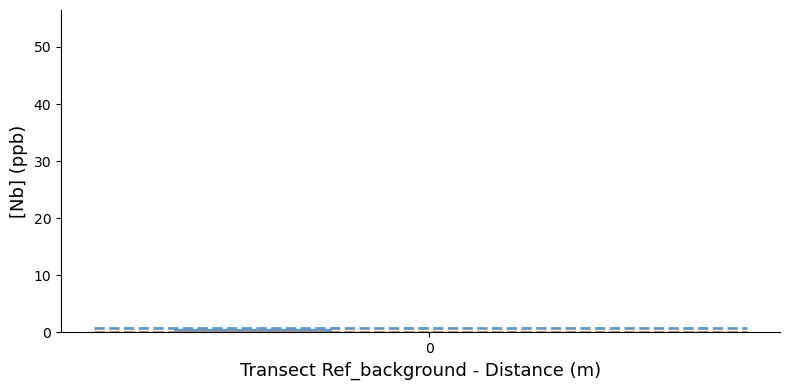

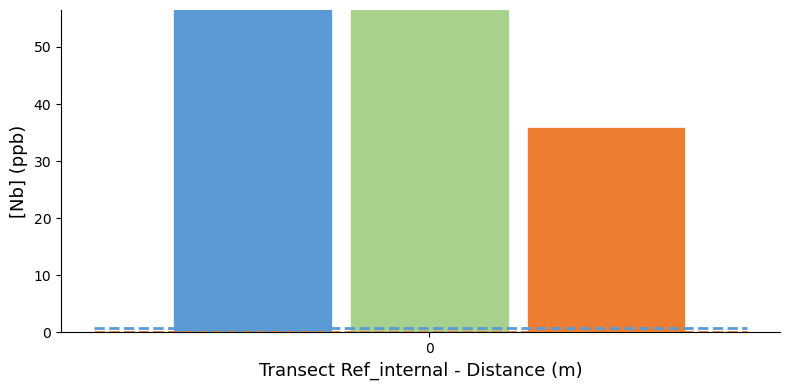

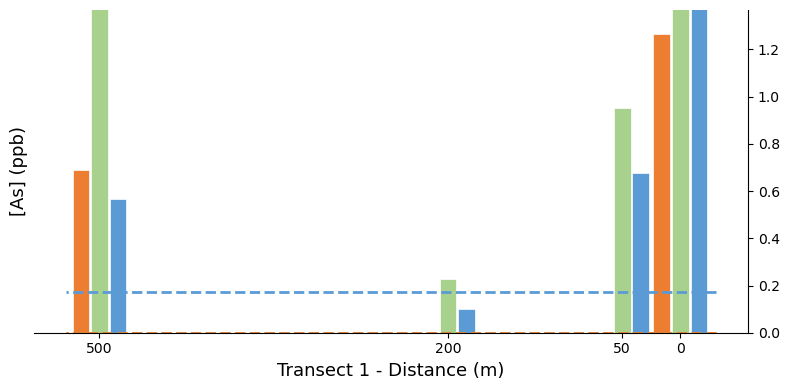

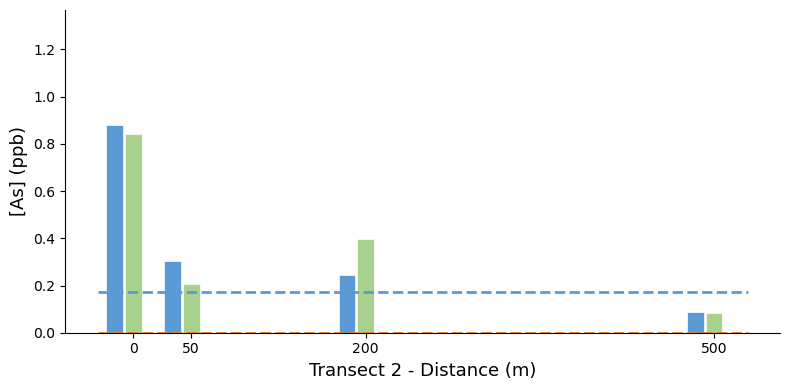

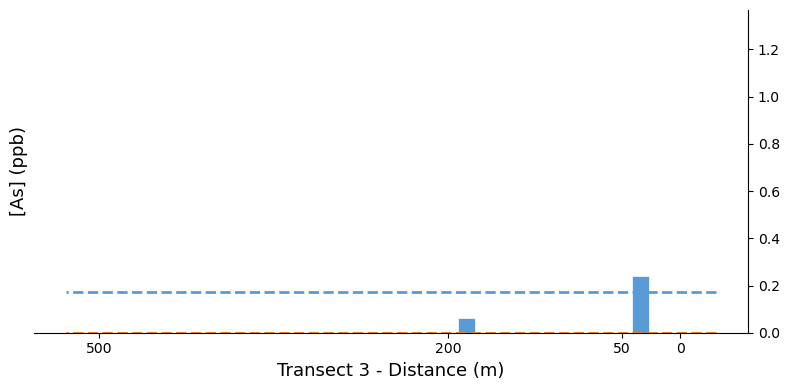

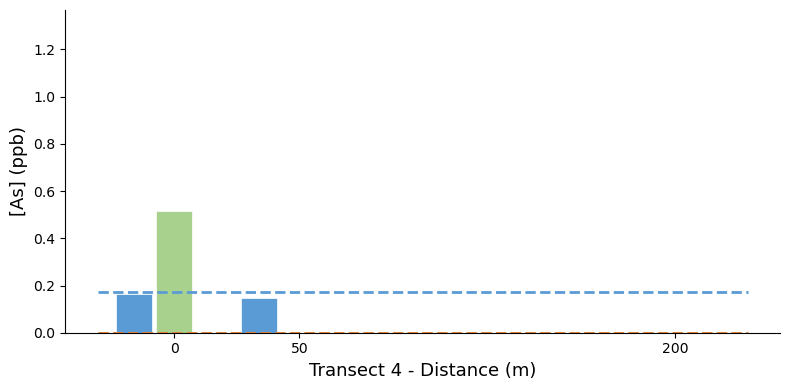

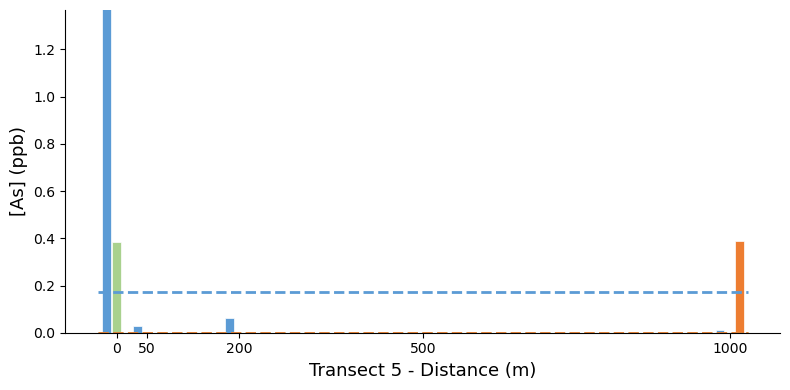

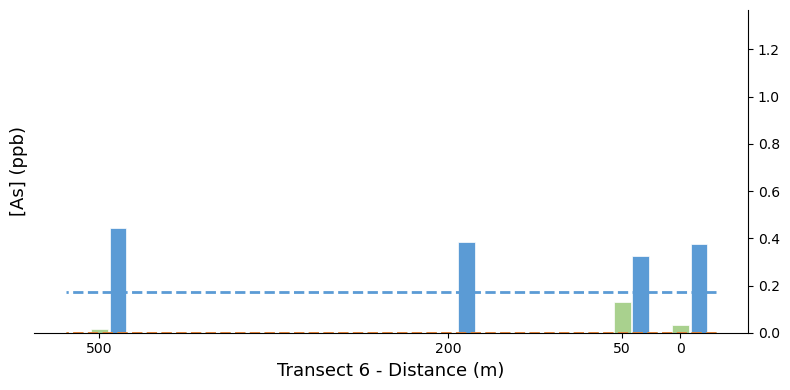

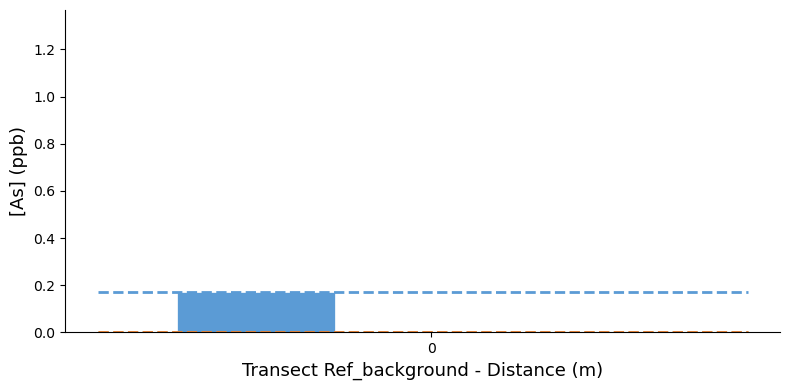

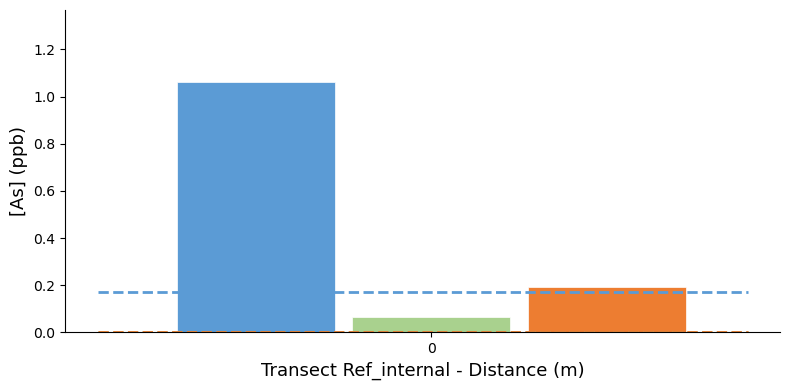

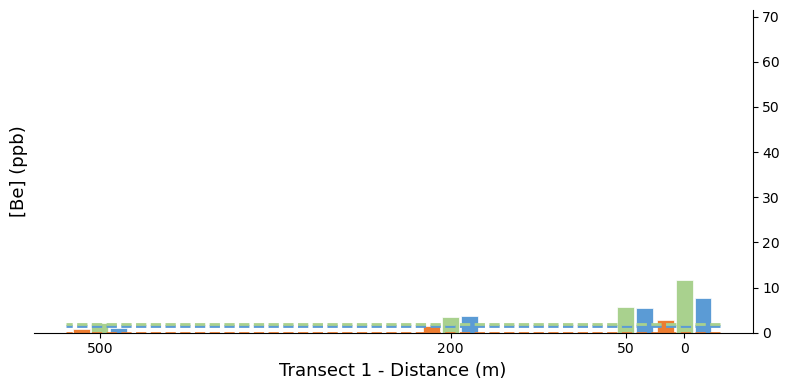

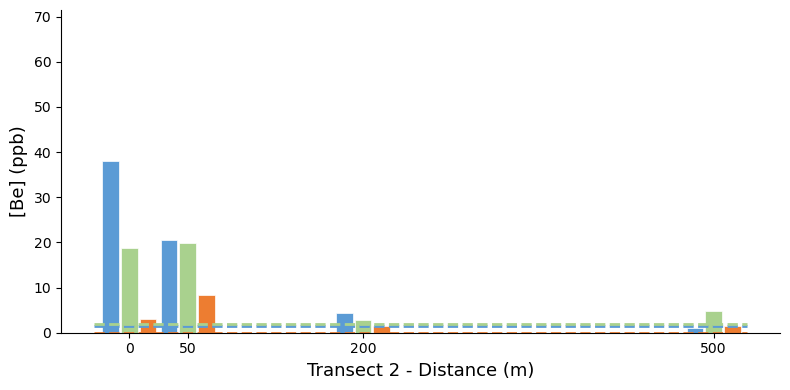

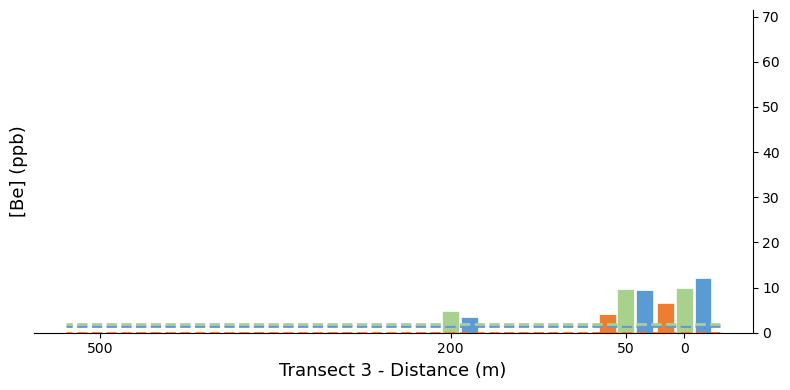

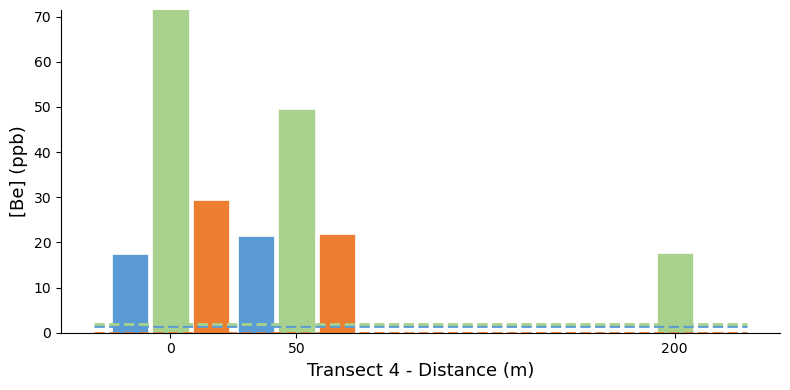

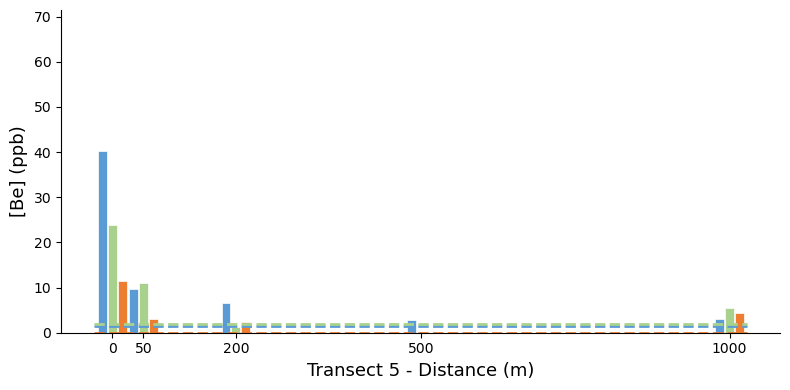

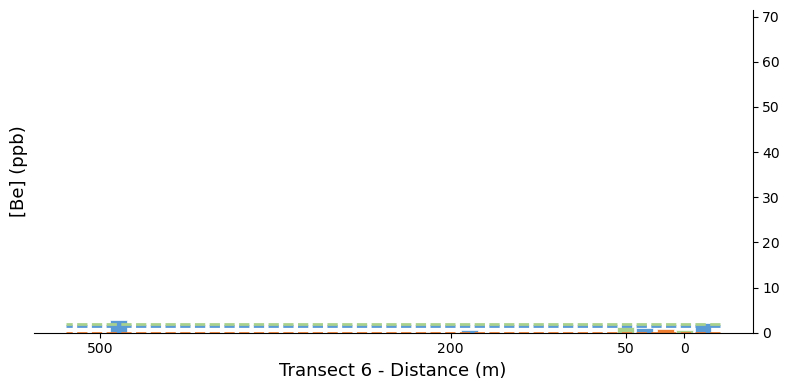

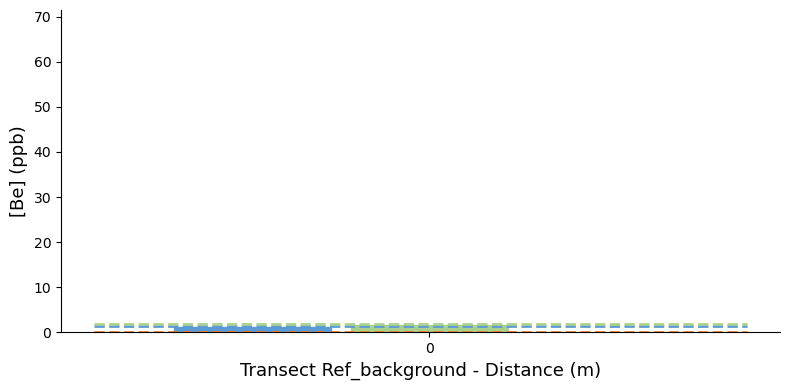

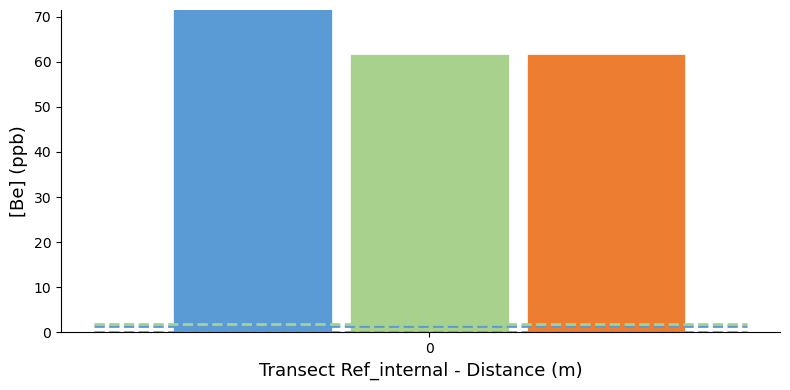

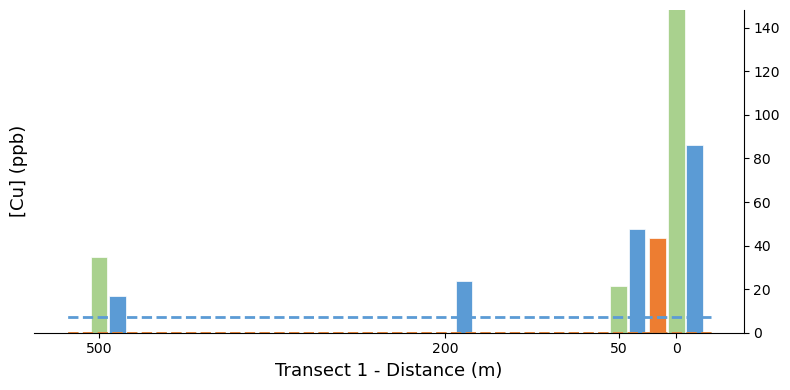

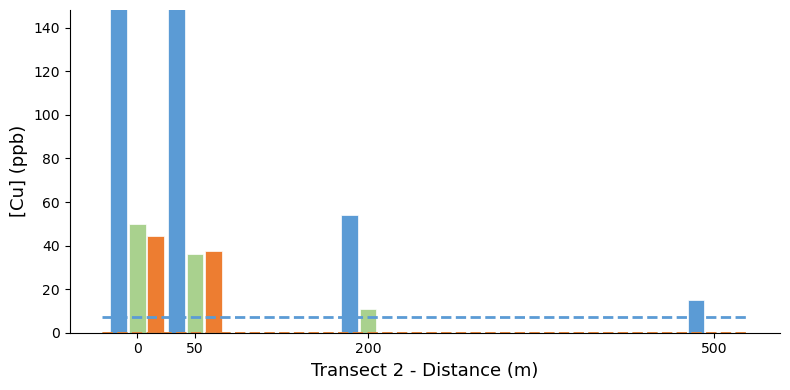

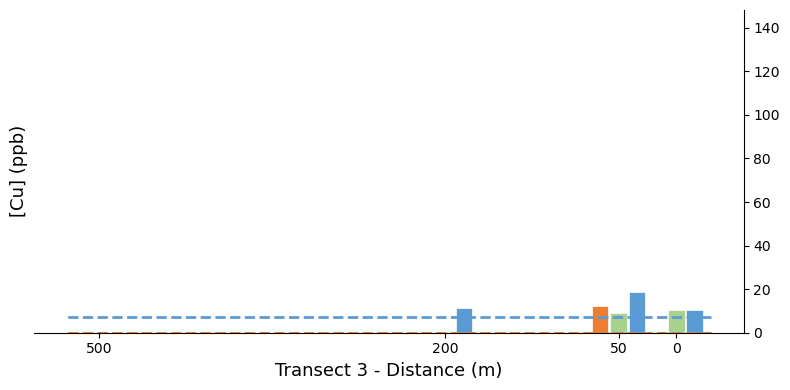

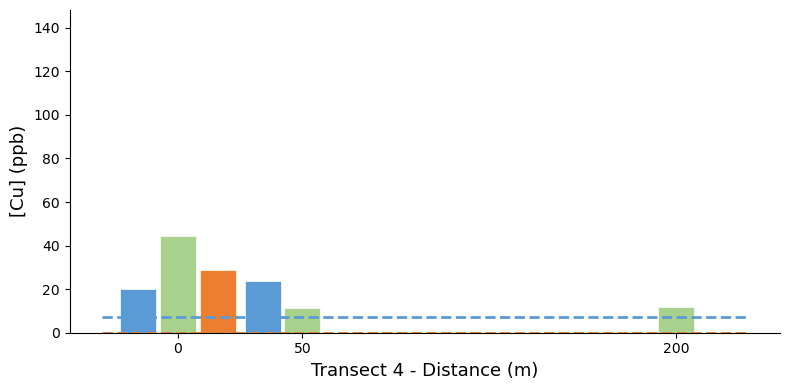

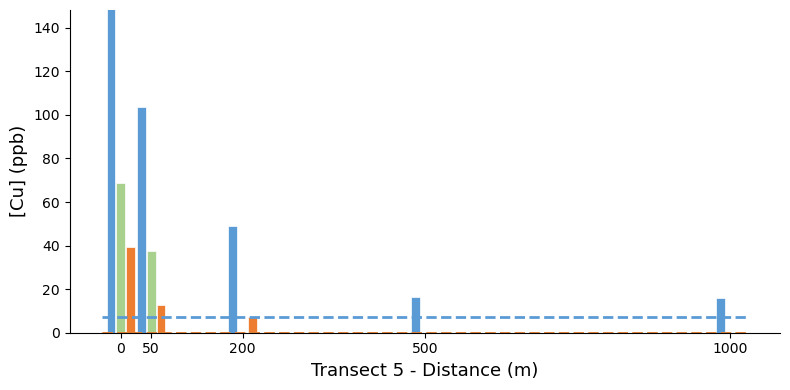

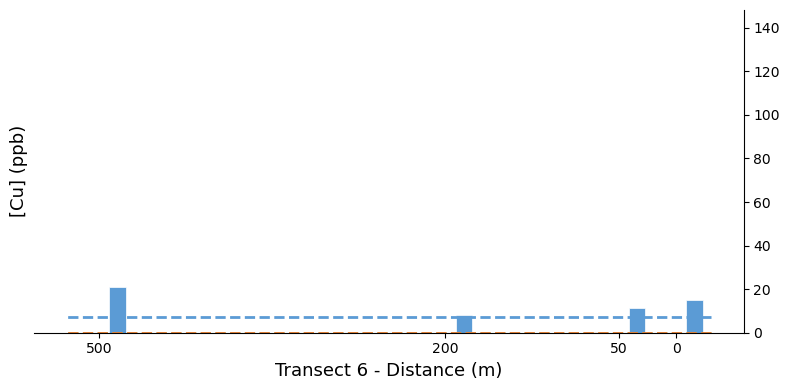

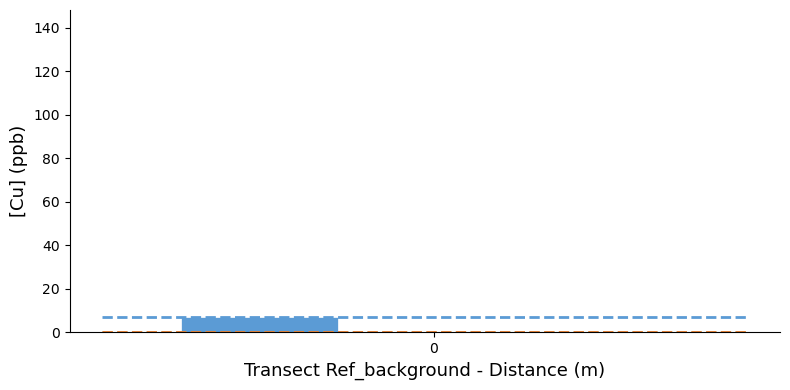

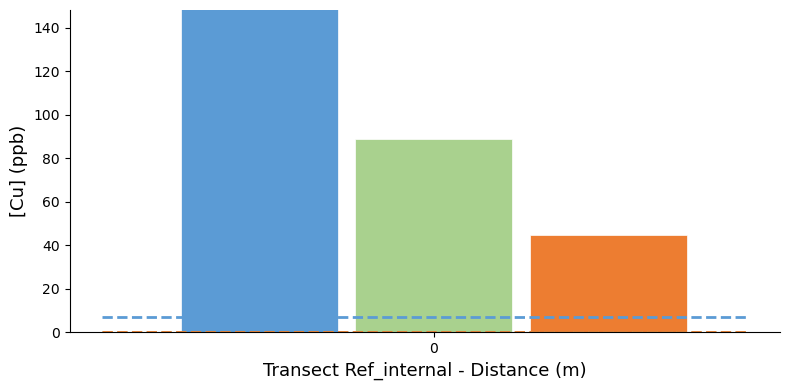

In [101]:
noaxis = False

for y_col in columns_interest:
	for tnumber in data['Transect'].unique():
		flip = tnumber in flips

		fig = plot_bar(data,tnumber, y_col, season_color=SEASON_COLORS,fig_size=(8, 4), show_legend=False,get_fig=True, flip=flip,noaxis=noaxis)
		if noaxis:
			plt.savefig(os.path.join(save_path,'noaxis',f'transect{tnumber}_elem-{y_col}.png'), dpi=200, transparent=True, bbox_inches="tight")
		else: 
			plt.savefig(os.path.join(save_path,f'transect{tnumber}_elem-{y_col}.png'), dpi=200, transparent=True, bbox_inches="tight")
		# plt.show()

In [102]:
data['Season'].unique()

array(['Winter 2024', 'Spring-Summer 2025', 'Fall 2025'], dtype=object)

Index(['Sample ID', 'Season', 'Dust sampler_ID', 'Transect', 'LatDecimal',
       'LonDecimal', 'LatDMS', 'LonDMS', 'distance', 'check ID',
       'Change in mass (mg)', '(mg/dm2/day)', '[Al] (ppm)', '[As] (ppm)',
       '[Ba] (ppm)', '[Bi] (ppm)', '[Ca] (ppm)', '[Cd] (ppm)', '[Co] (ppm)',
       '[Cr] (ppm)', '[Cu] (ppm)', '[Fe] (ppm)', '[K] (ppm)', '[Li] (ppm)',
       '[Mg] (ppm)', '[Mn] (ppm)', '[Mo] (ppm)', '[Na] (ppm)', '[Ni] (ppm)',
       '[P] (ppm)', '[Pb] (ppm)', '[S (ICP)] (ppm)', '[Sb] (ppm)',
       '[Se] (ppm)', '[Si] (ppm)', '[Sr] (ppm)', '[Ti] (ppm)', '[V] (ppm)',
       '[Zn] (ppm)', '[Zr] (ppm)', '[As] (ppb)', '[Ba] (ppb)', '[Be] (ppb)',
       '[Ce] (ppb)', '[Co] (ppb)', '[Cr] (ppb)', '[Cu] (ppb)', '[Li] (ppb)',
       '[Nb] (ppb)', '[Pb] (ppb)', '[Rb] (ppb)', '[Tl] (ppb)', '[V] (ppb)'],
      dtype='object')

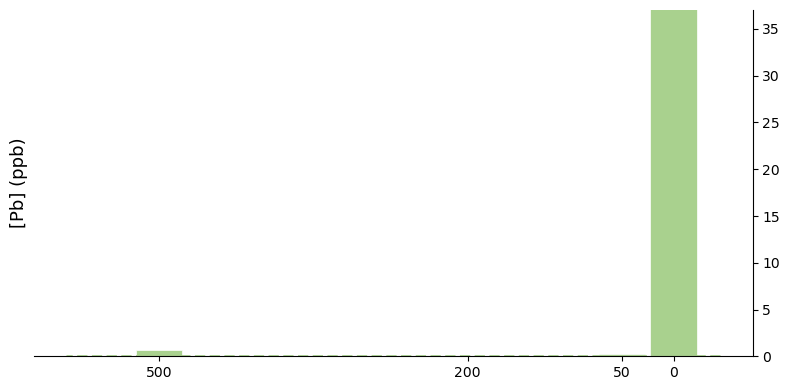

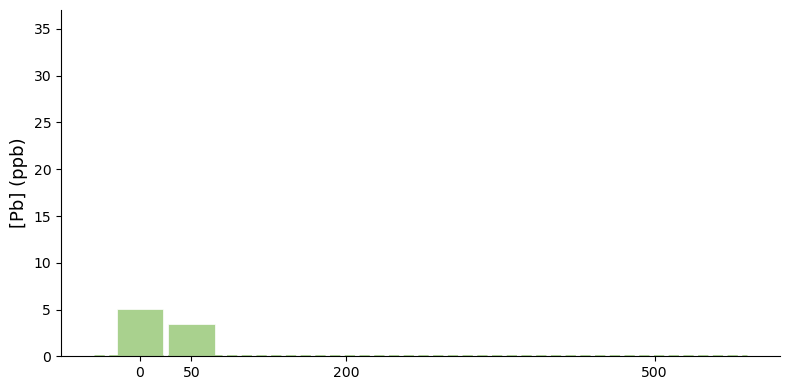

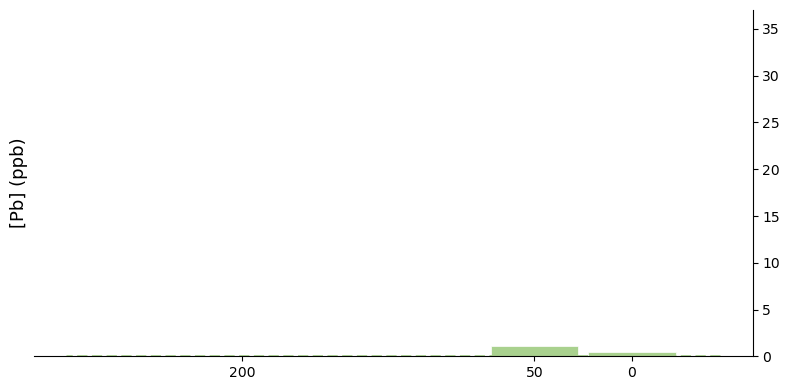

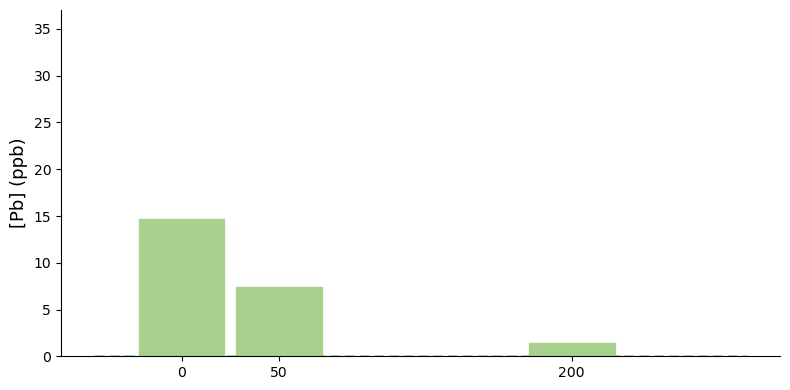

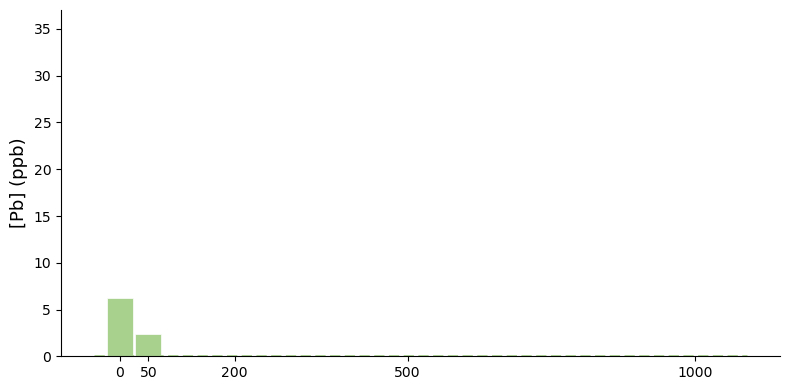

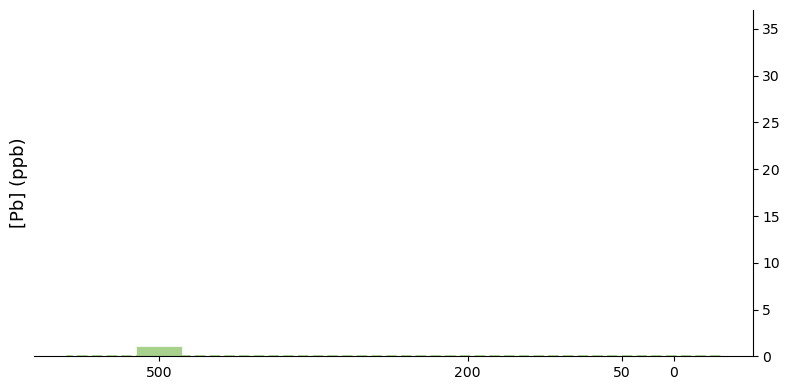

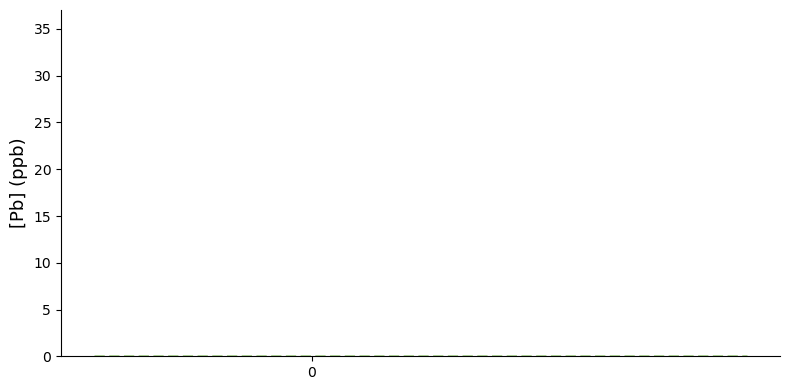

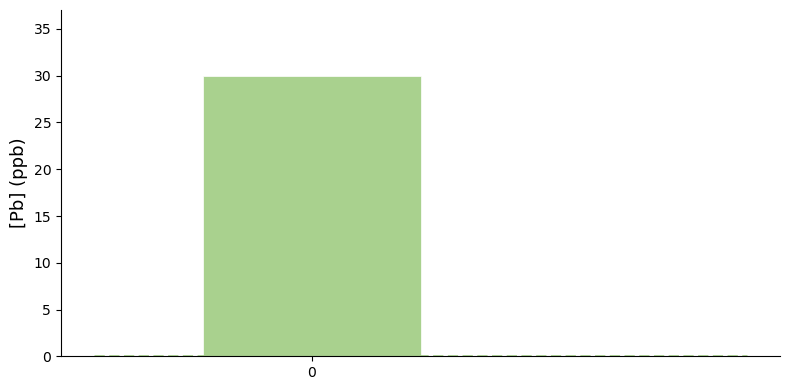

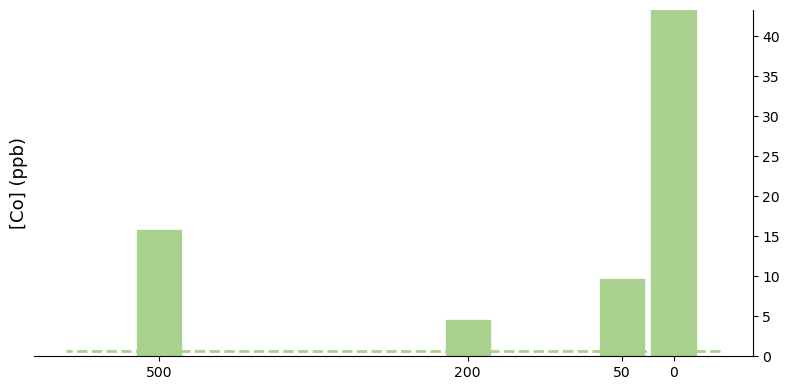

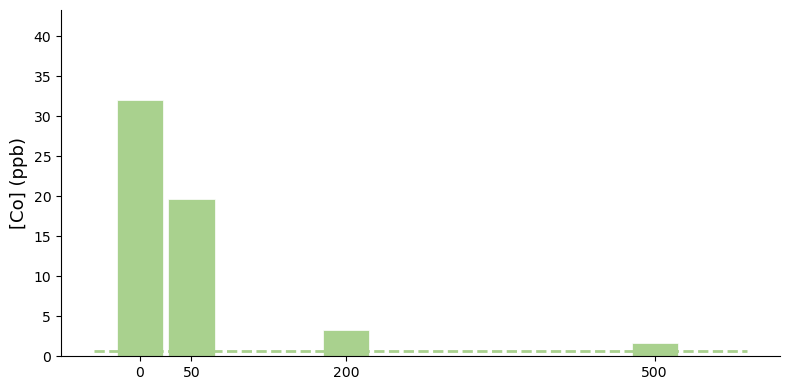

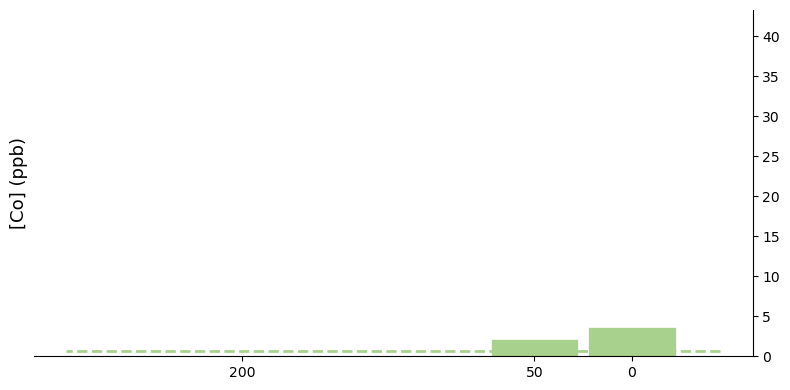

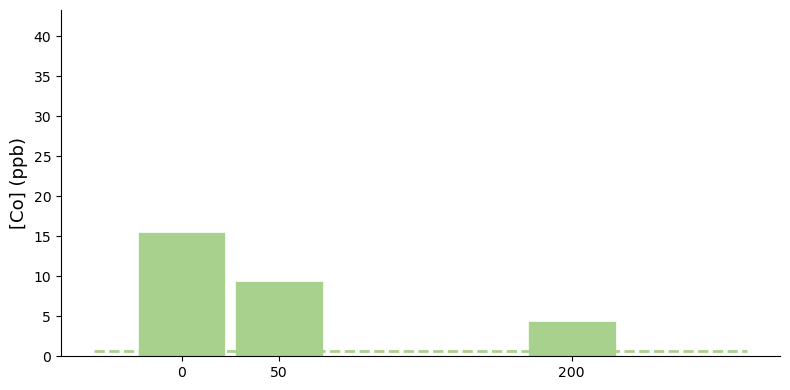

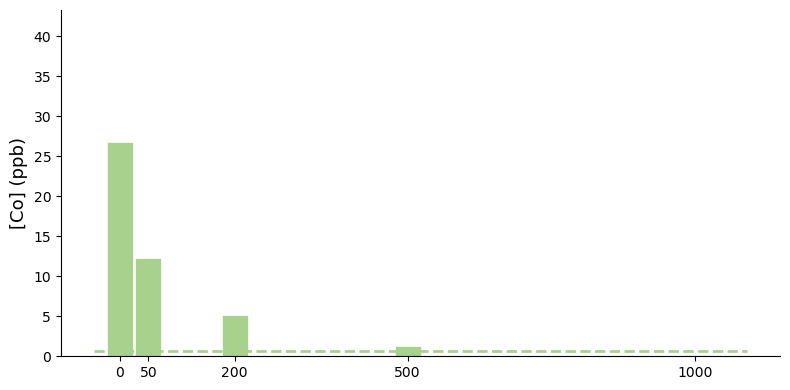

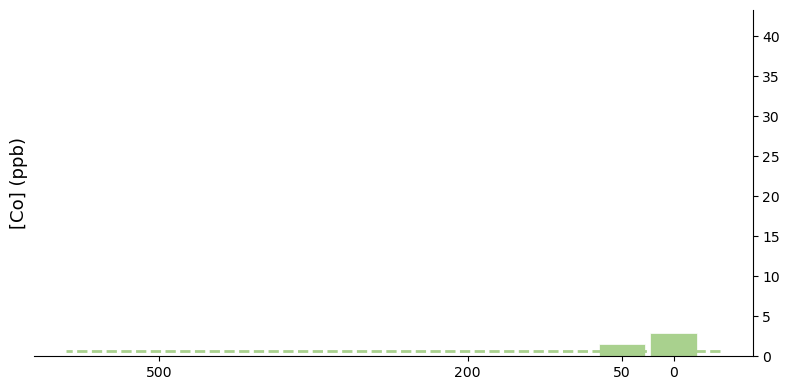

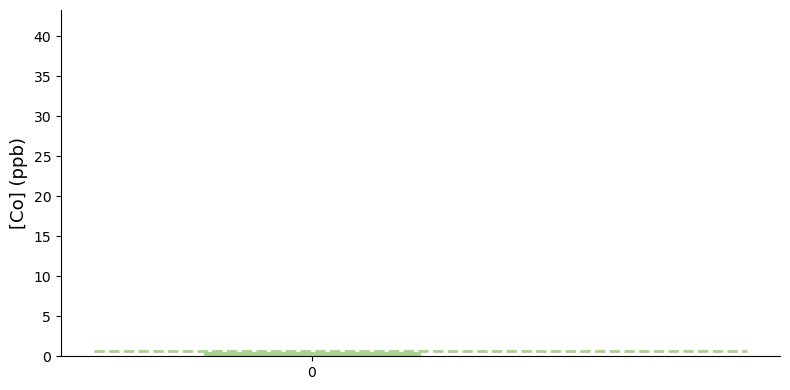

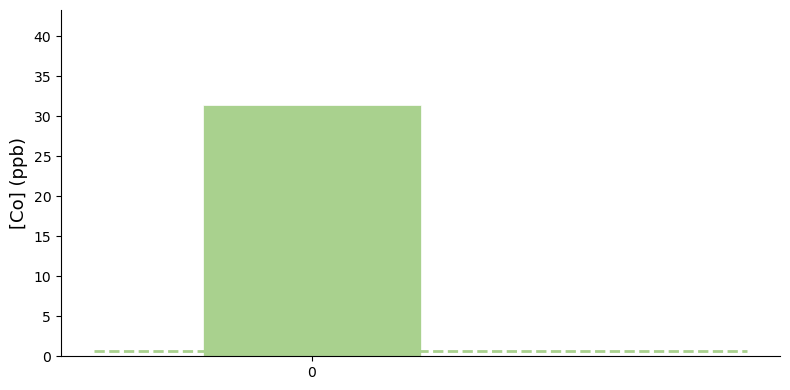

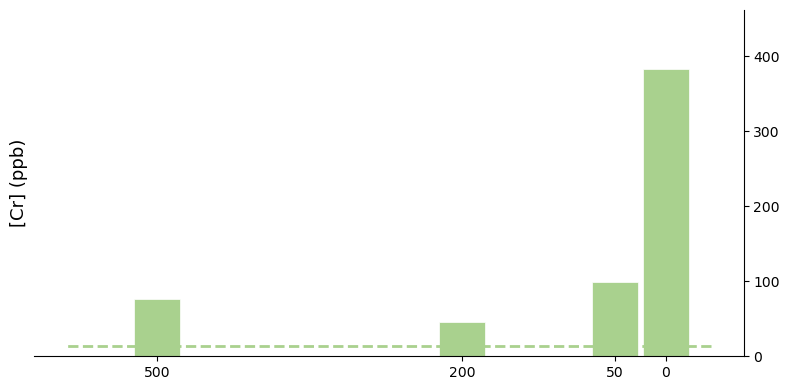

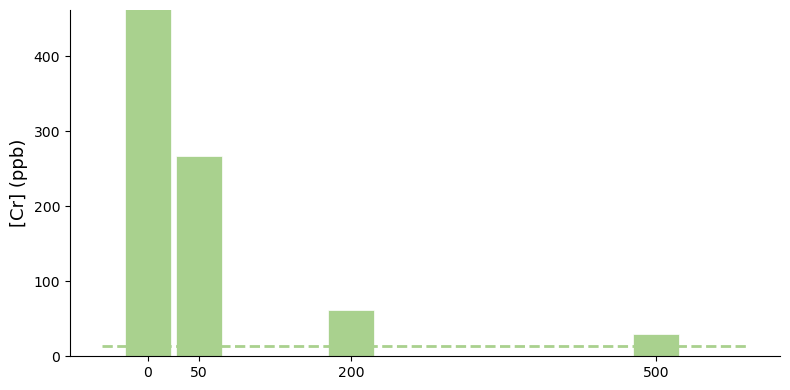

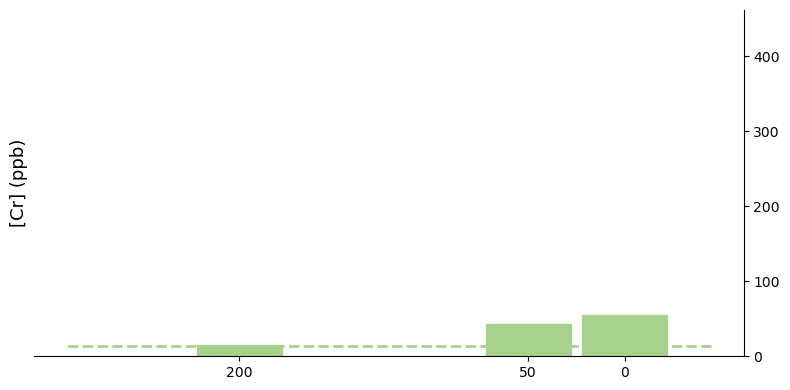

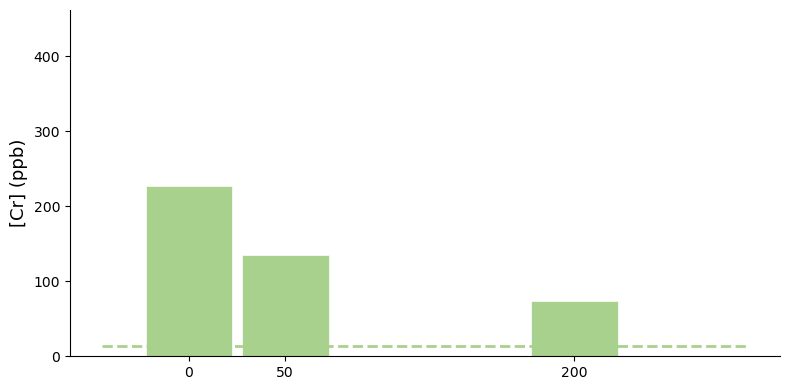

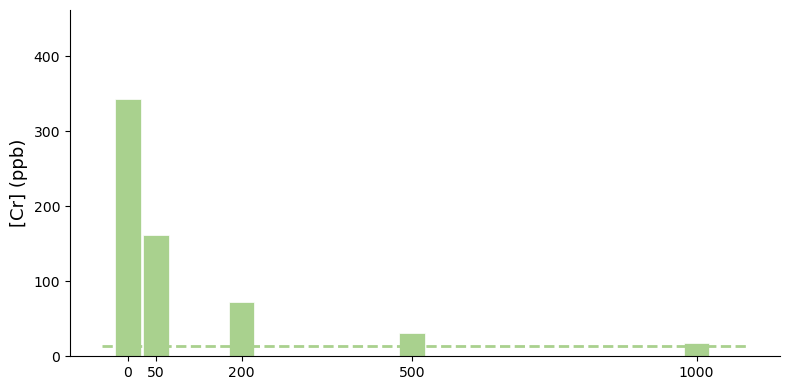

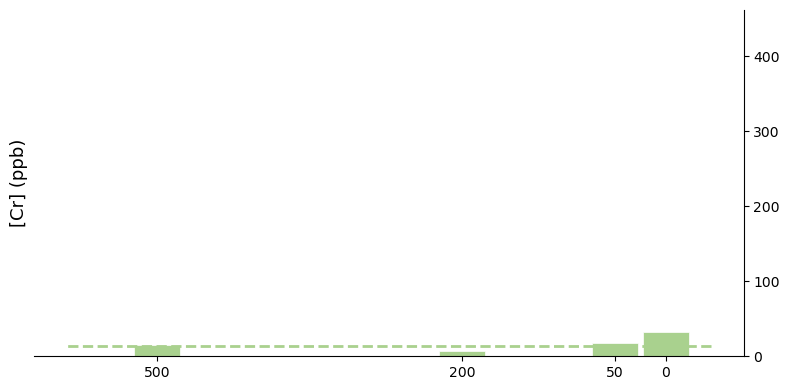

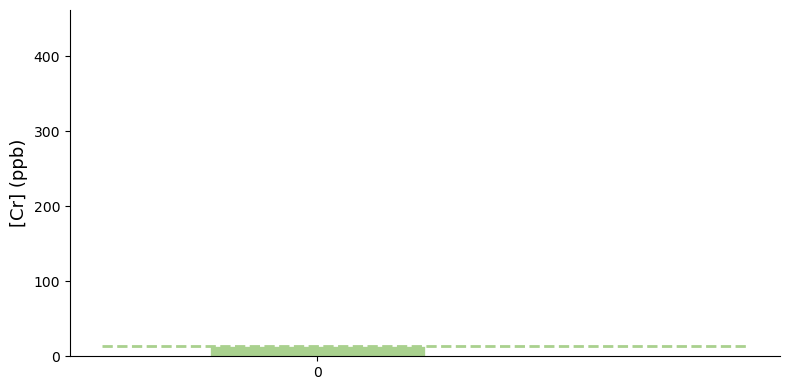

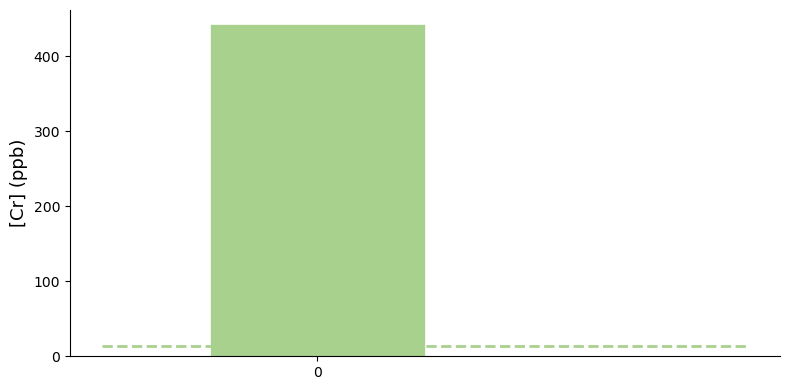

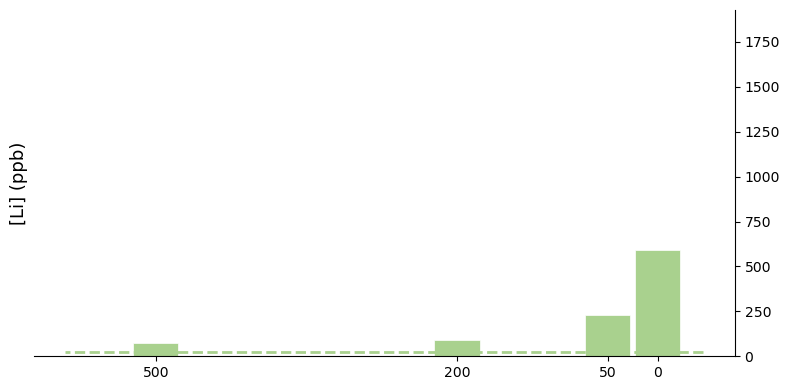

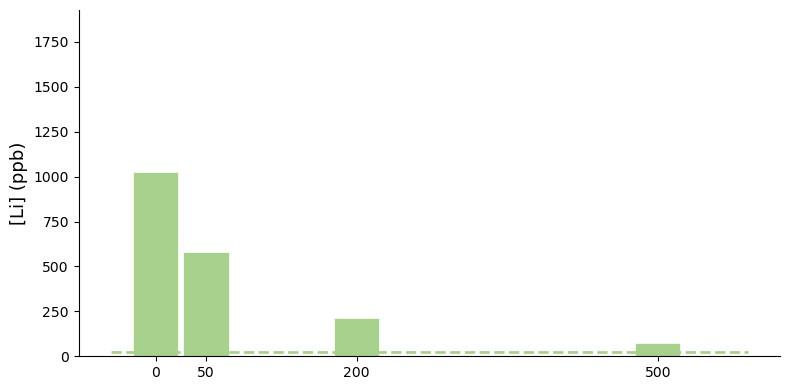

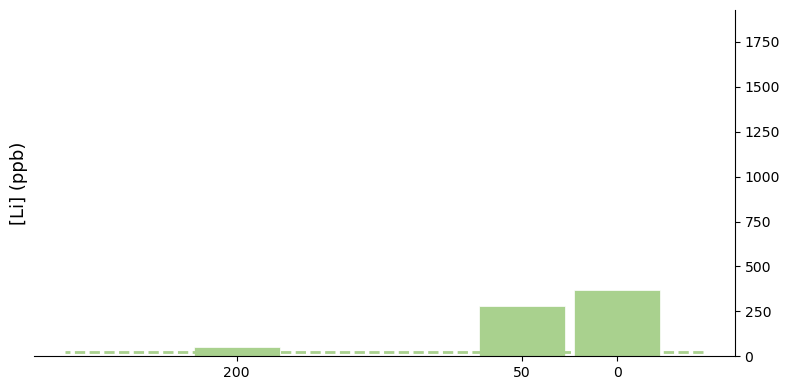

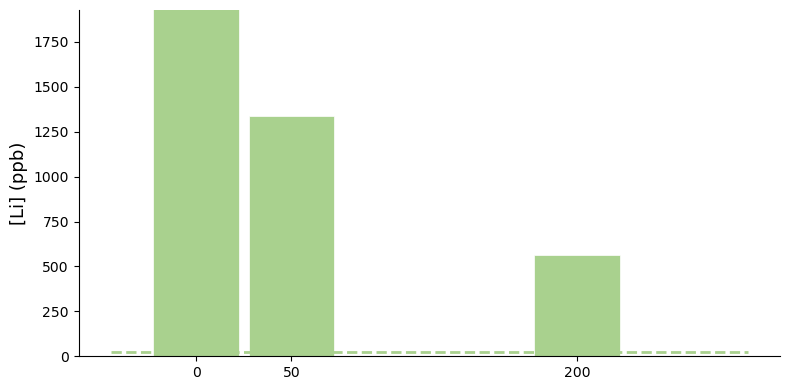

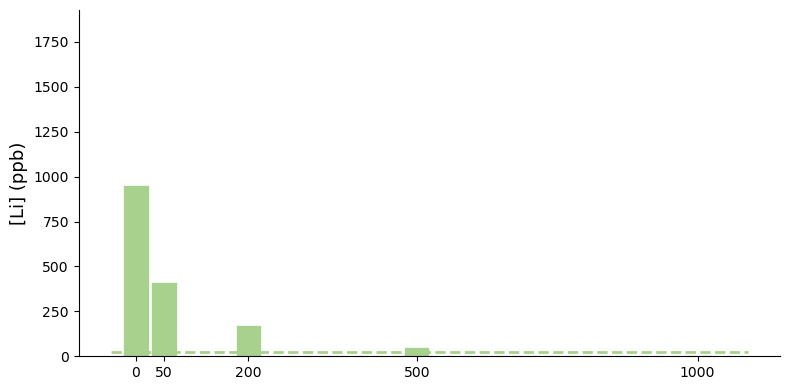

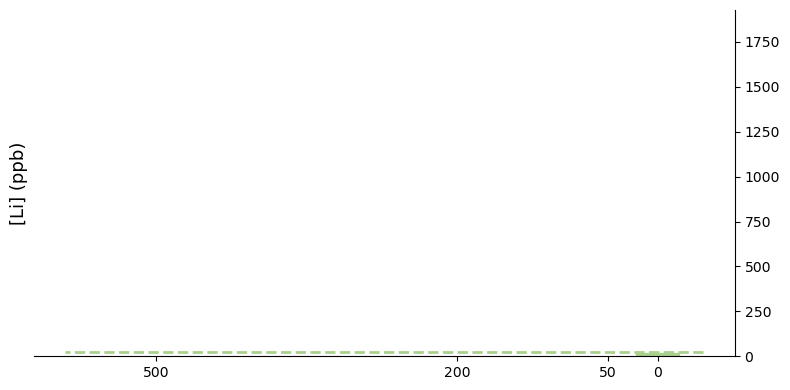

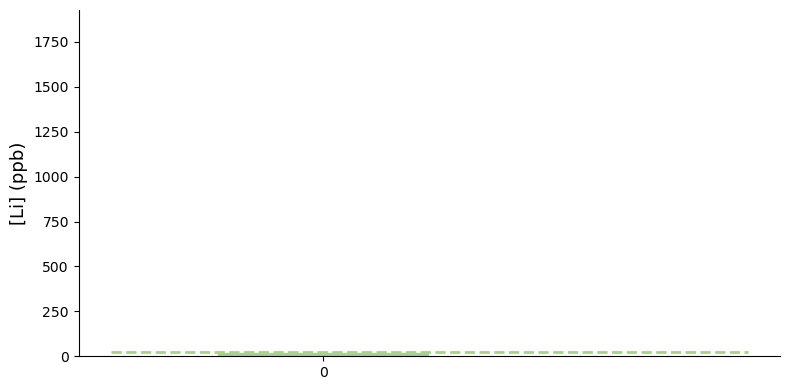

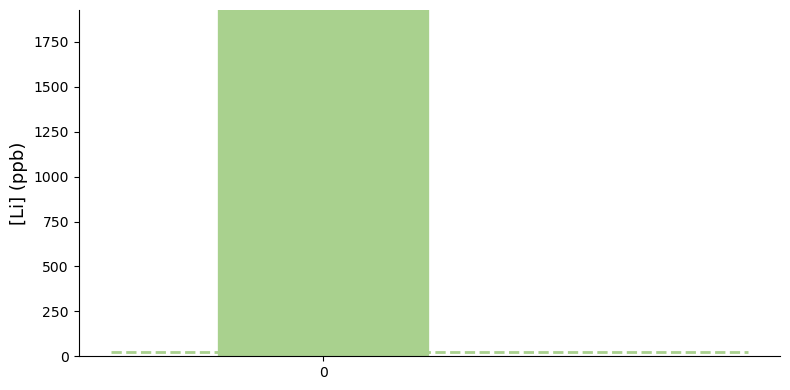

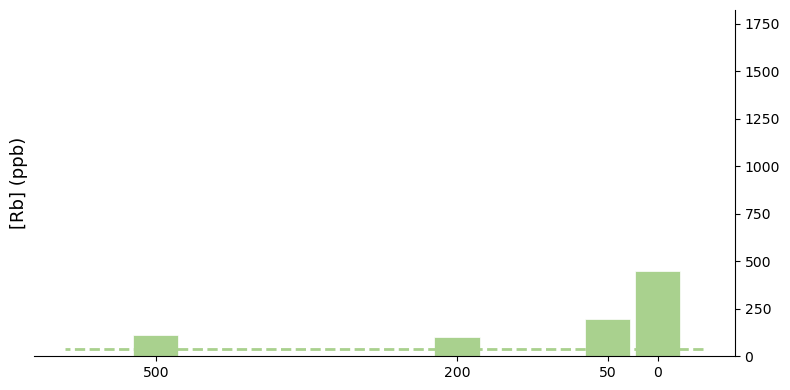

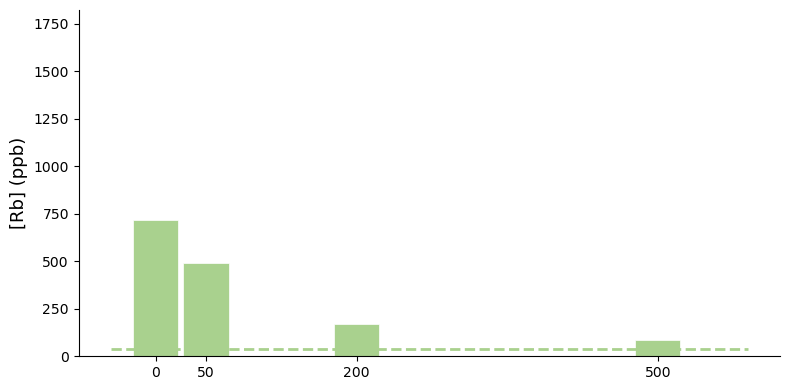

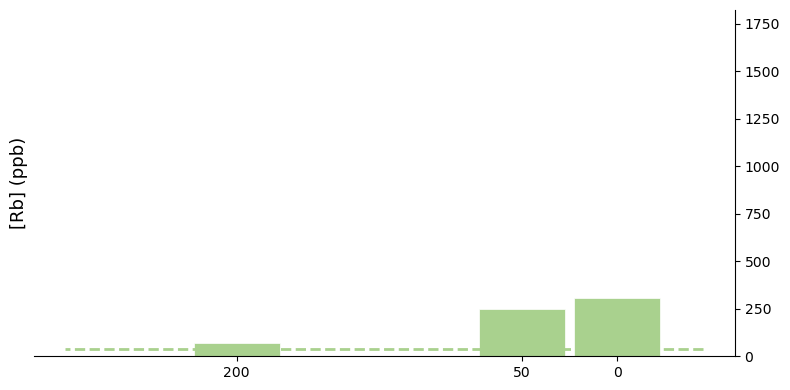

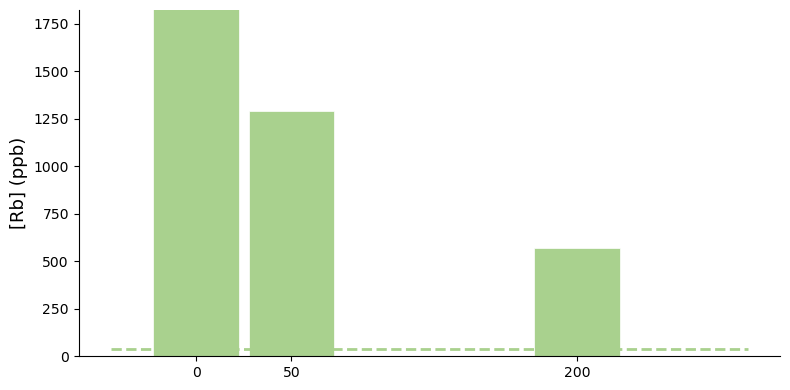

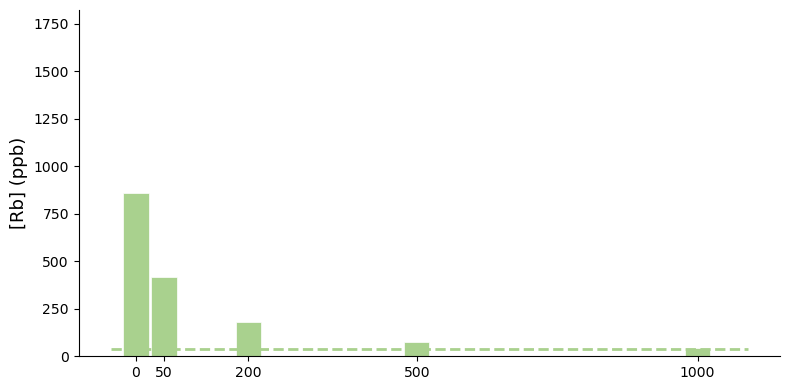

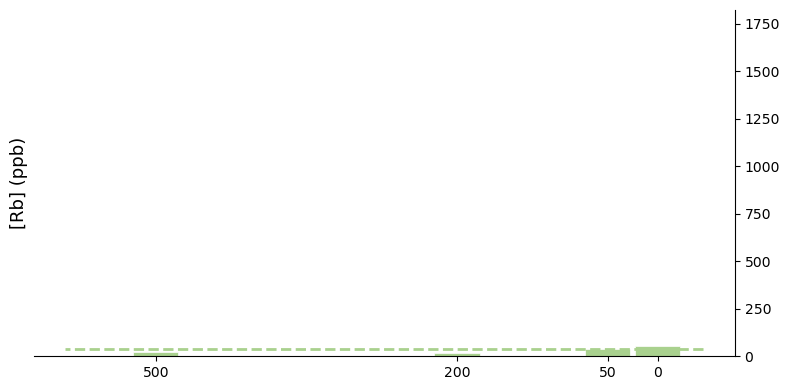

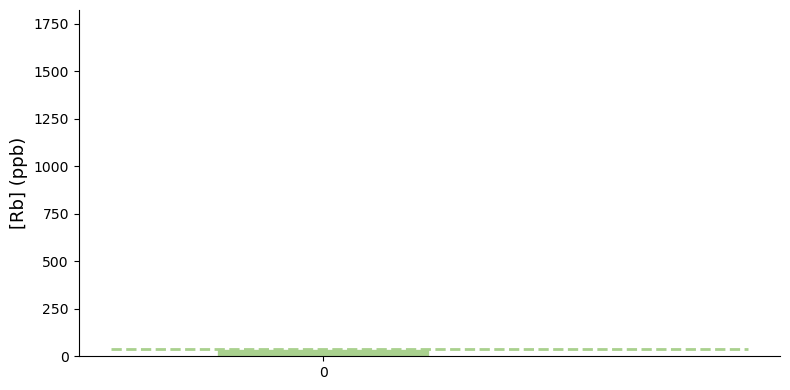

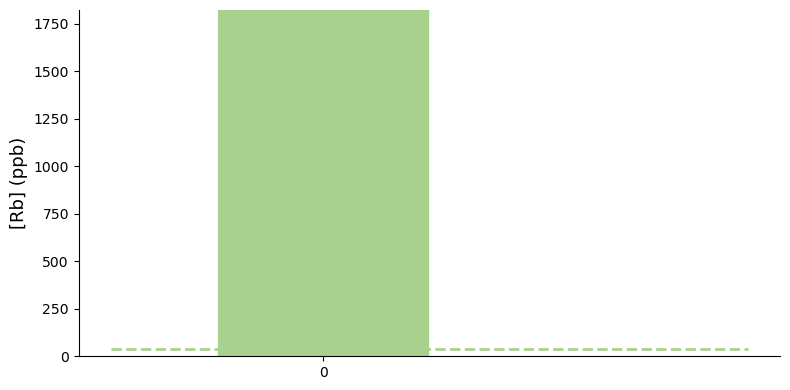

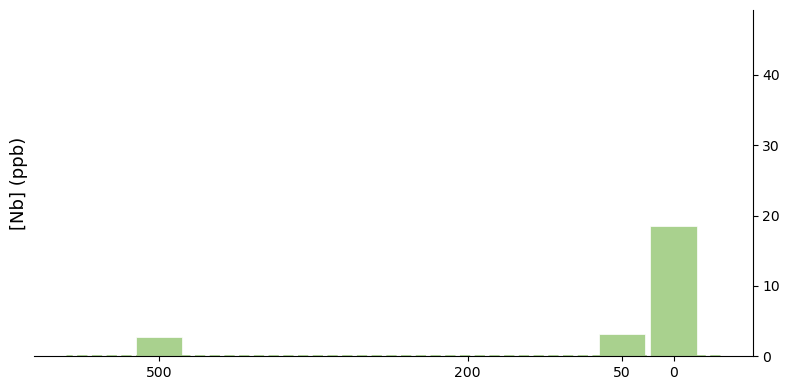

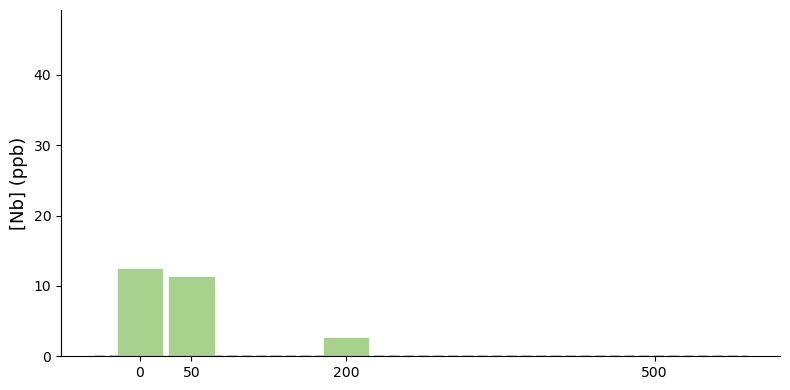

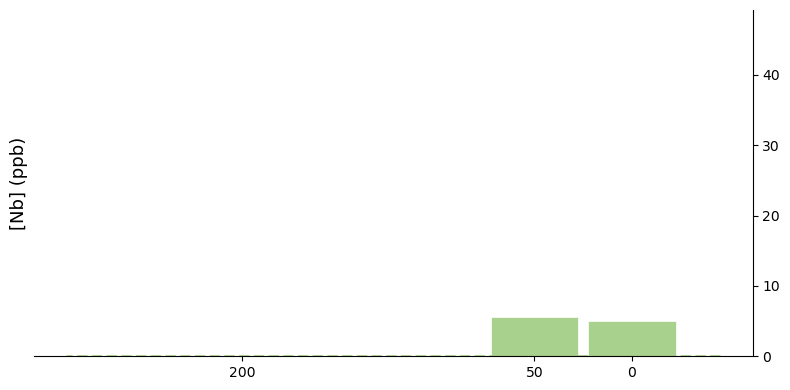

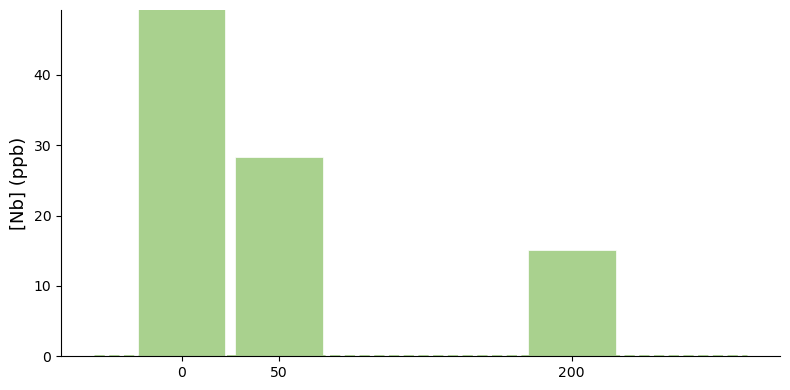

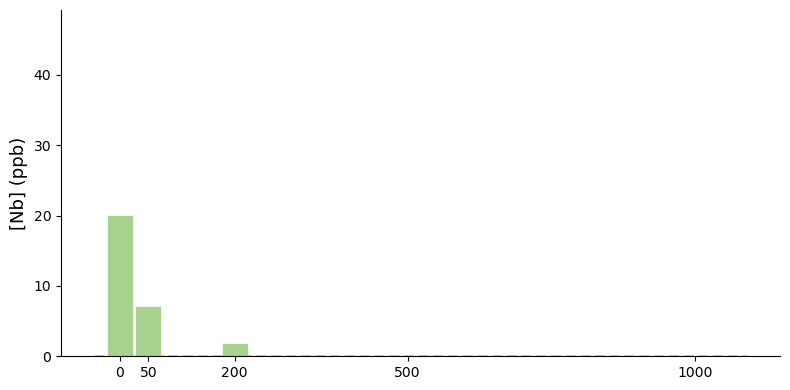

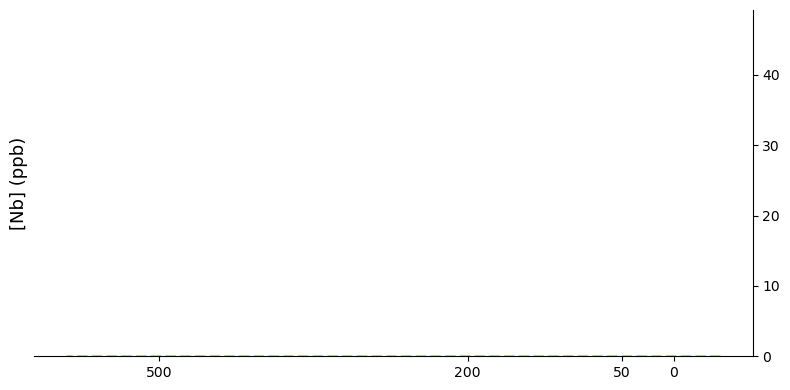

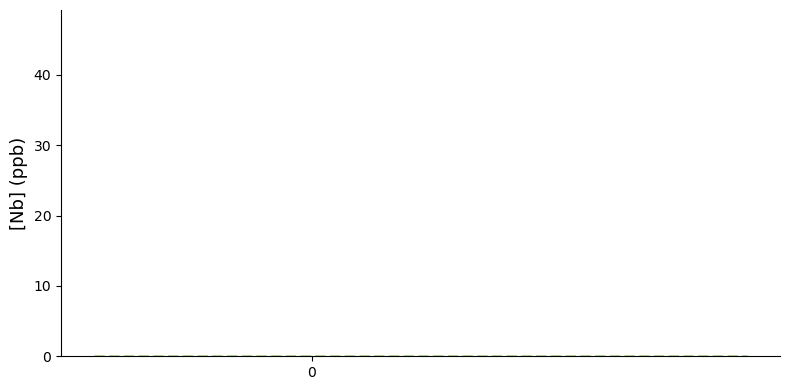

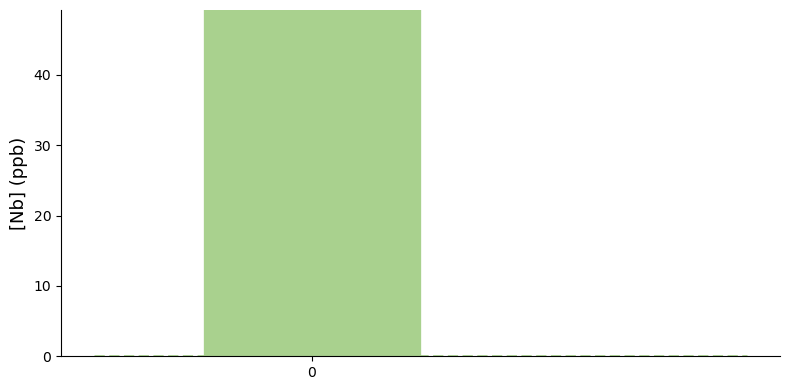

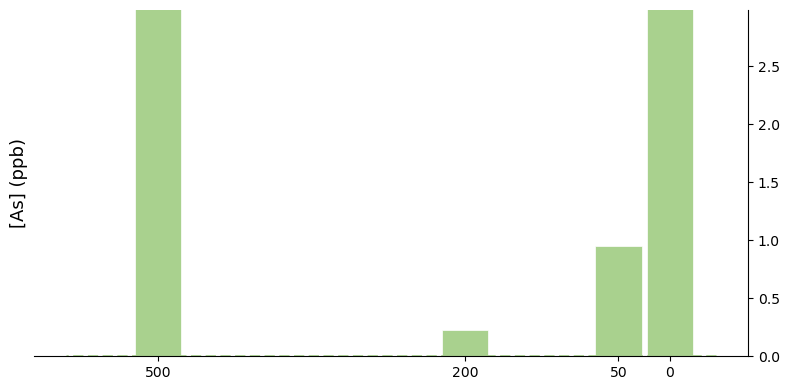

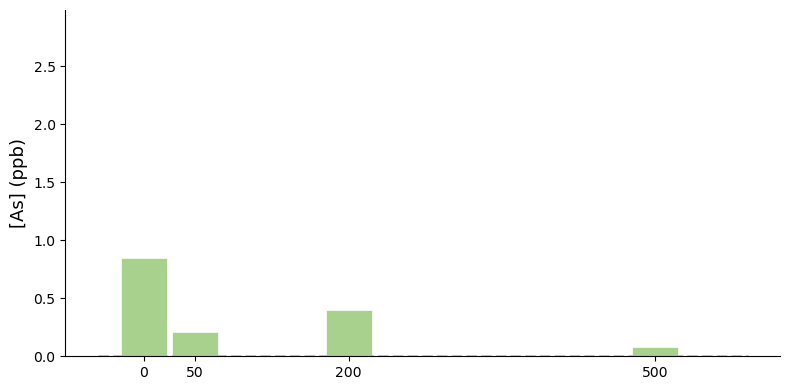

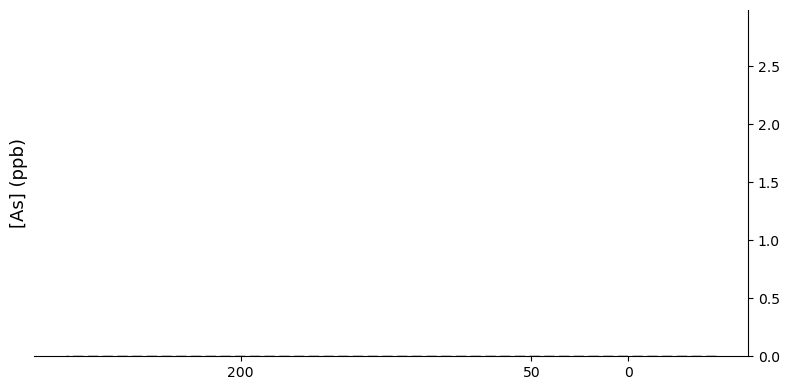

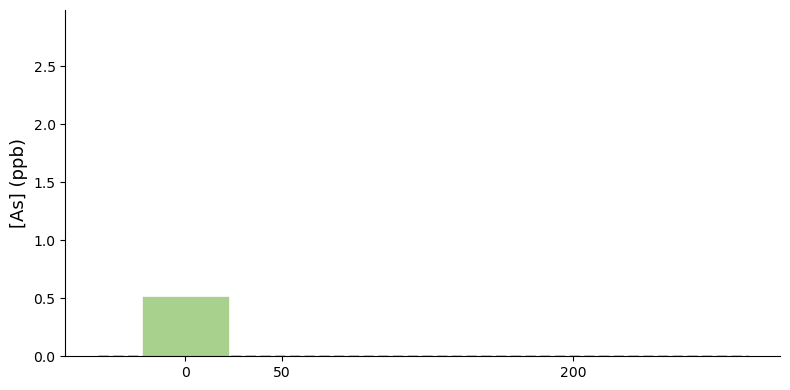

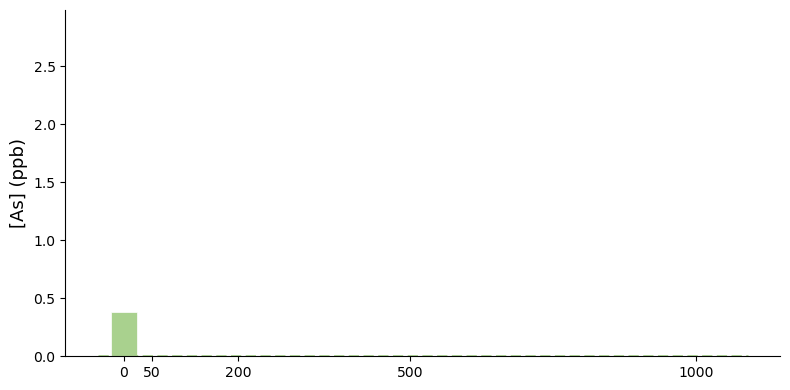

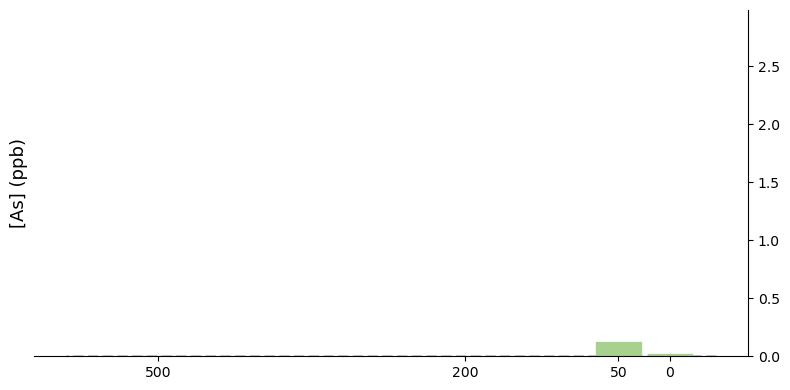

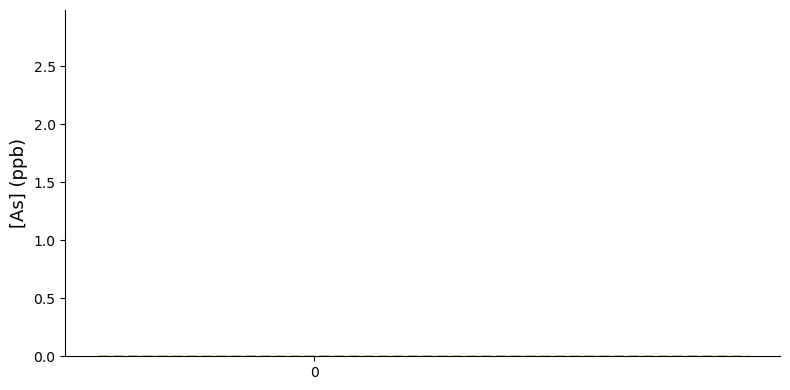

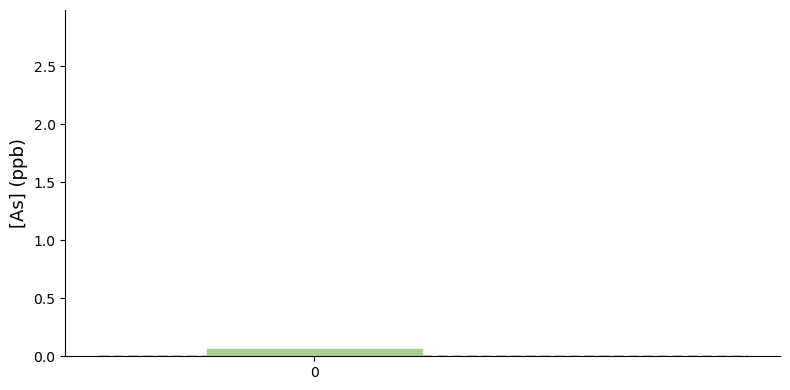

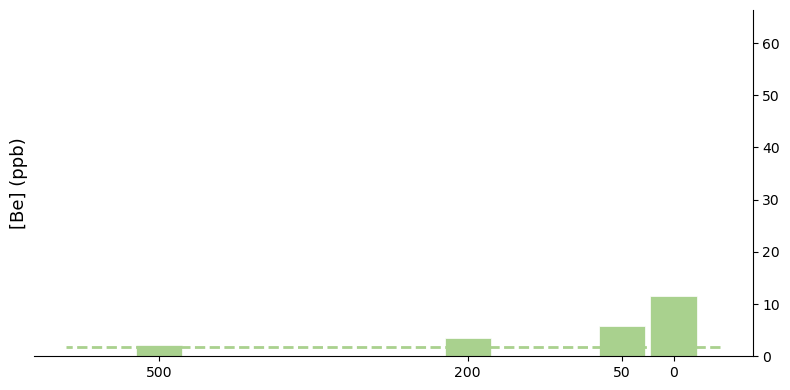

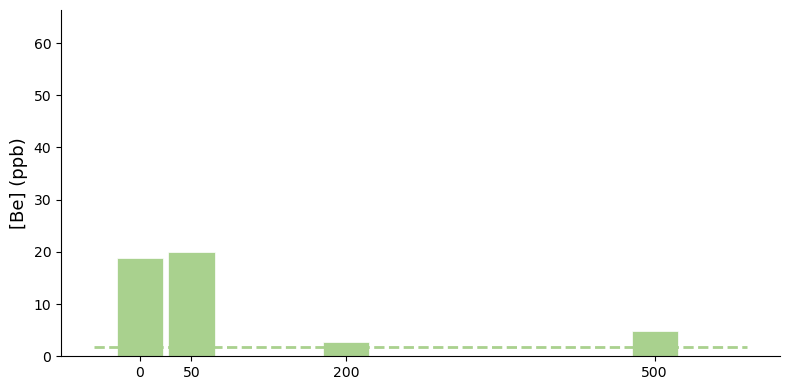

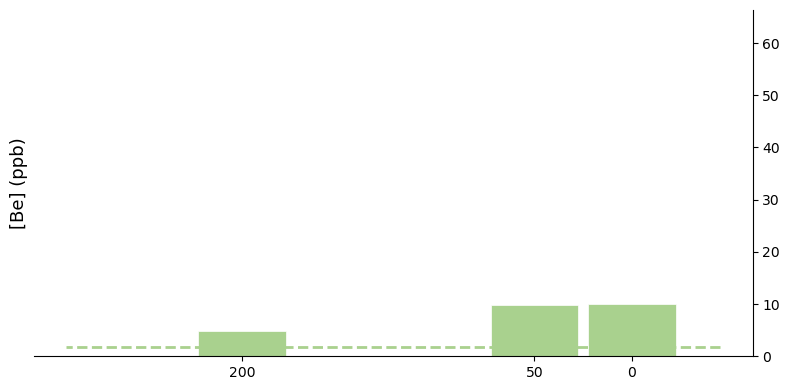

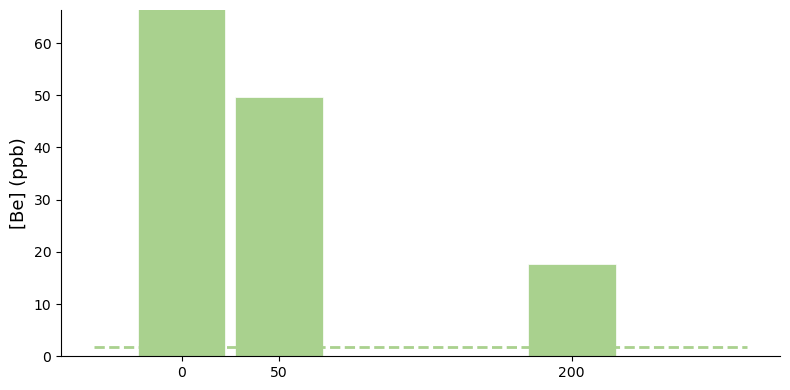

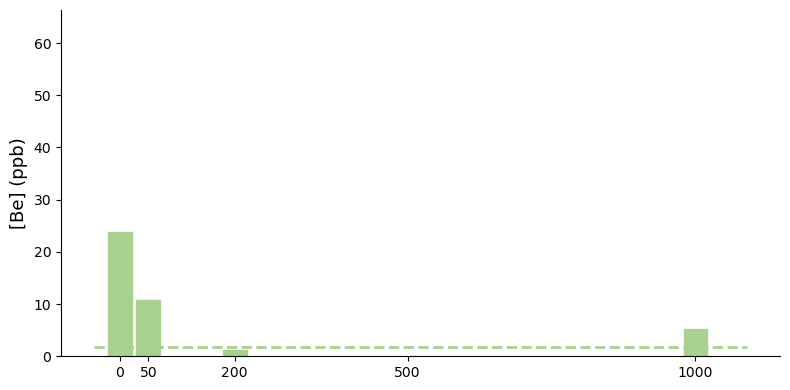

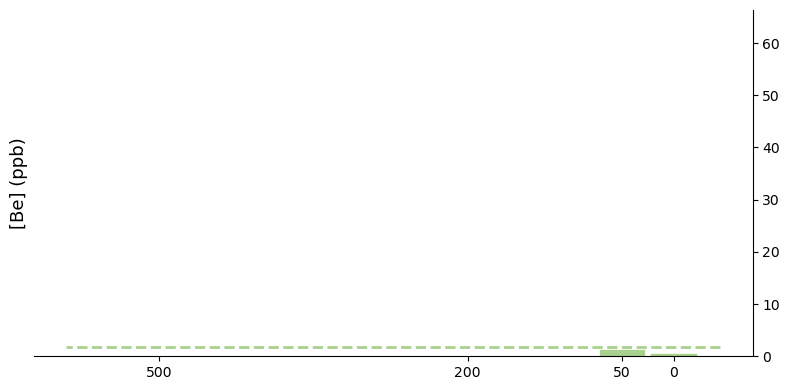

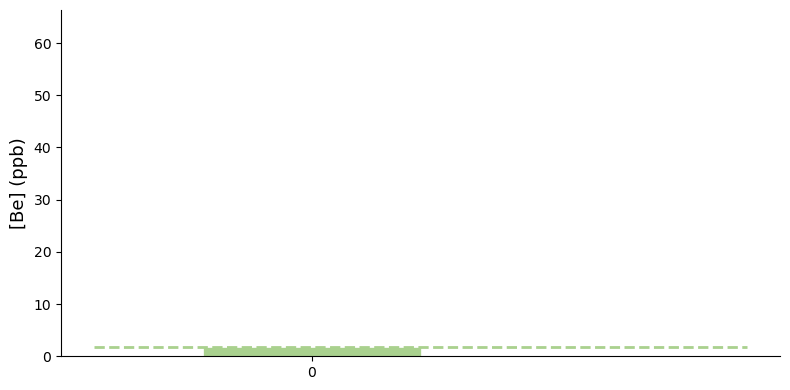

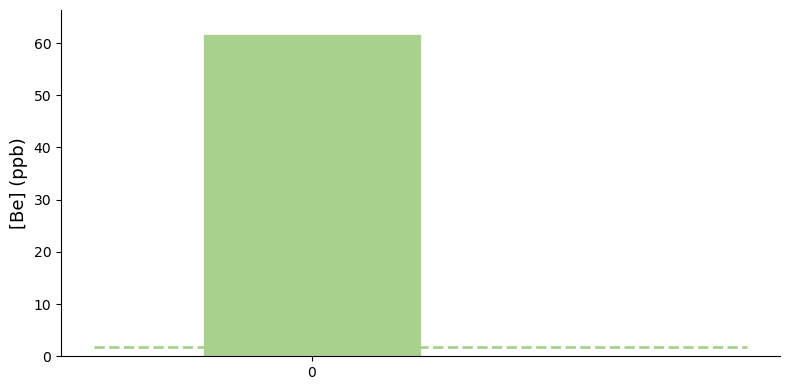

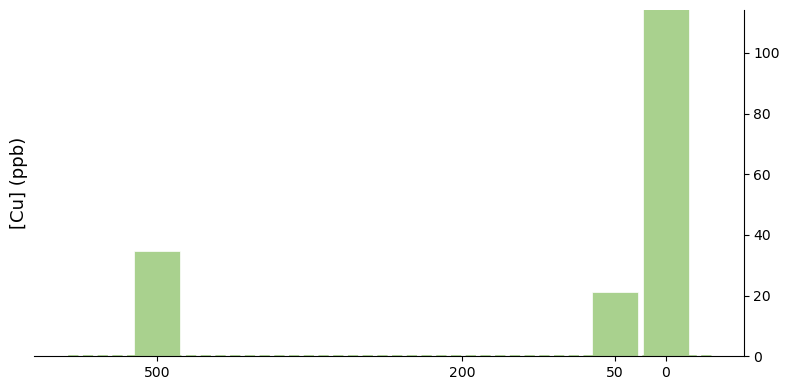

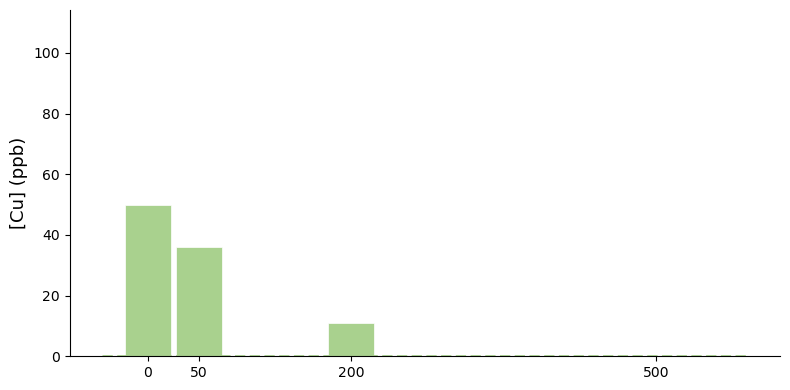

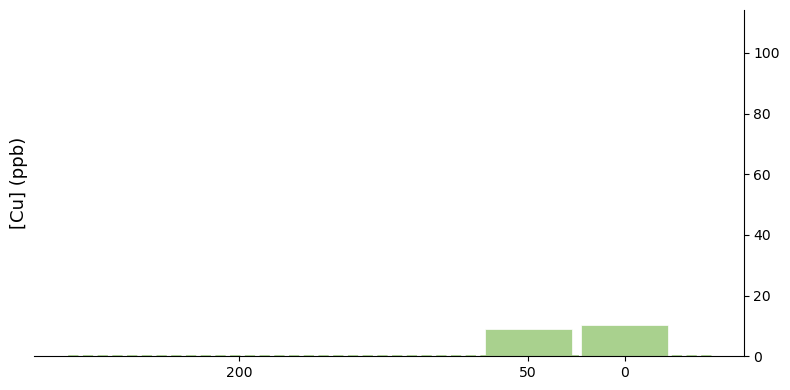

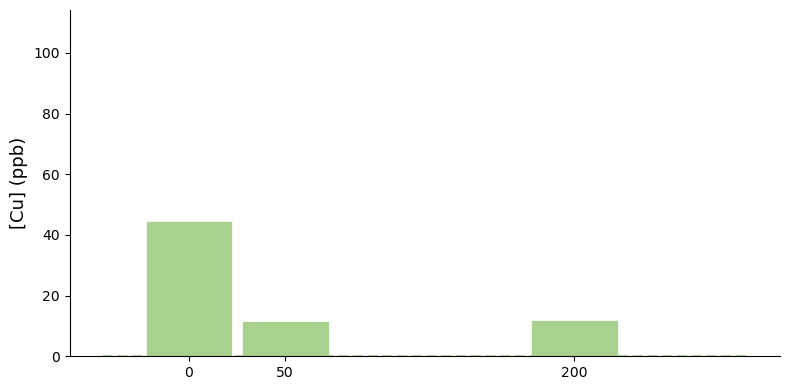

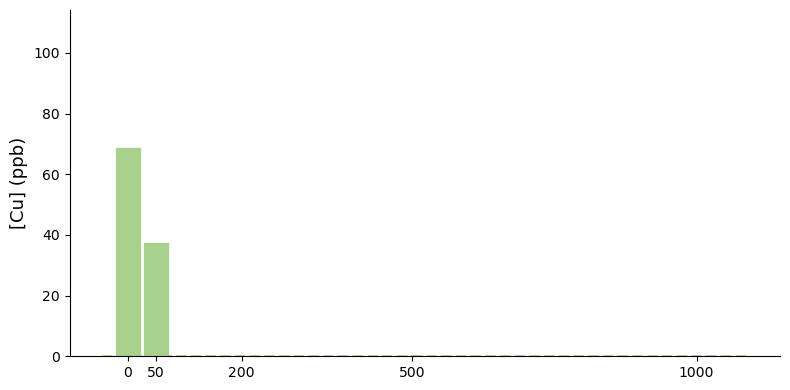

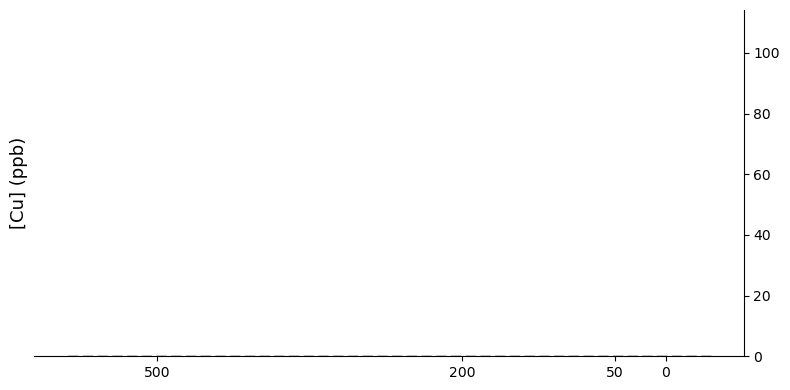

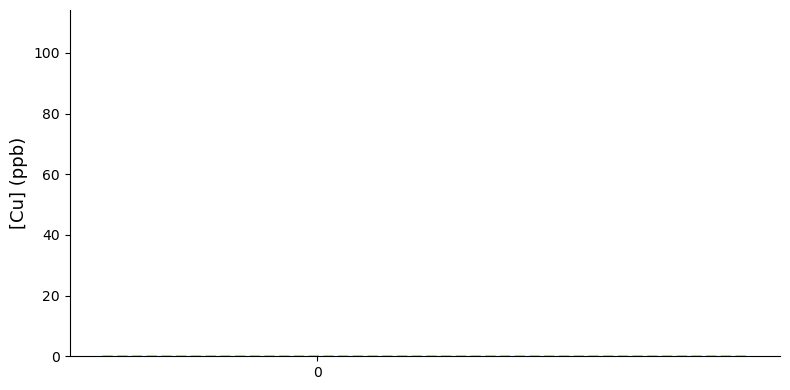

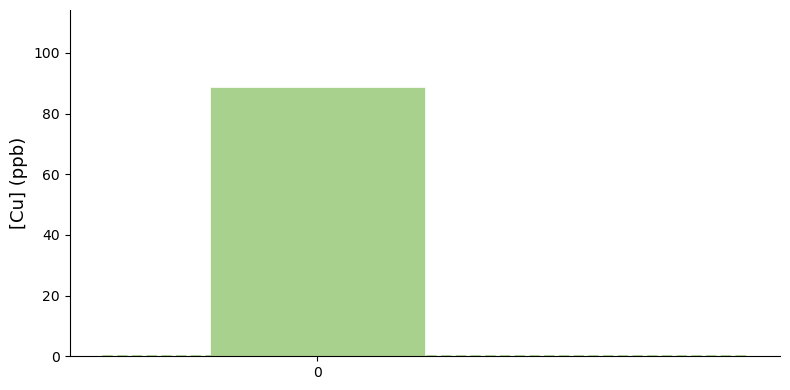

In [69]:
noaxis = True
season = 'Spring-Summer 2025'
season_data = data[data['Season'] == season]

for y_col in columns_interest:
	for tnumber in season_data['Transect'].unique():
		flip = tnumber in flips

		fig = plot_bar(season_data,tnumber, y_col, season_color=SEASON_COLORS,fig_size=(8, 4), show_legend=False,get_fig=True, flip=flip,noaxis=noaxis,bar_width = 50)
		if noaxis:
			plt.savefig(os.path.join(save_path,'noaxis',f'transect{tnumber}_elem-{y_col}_{season}.png'), dpi=200, transparent=True, bbox_inches="tight")
		else: 
			plt.savefig(os.path.join(save_path,f'transect{tnumber}_elem-{y_col}_{season}.png'), dpi=200, transparent=True, bbox_inches="tight")
		plt.show()

In [70]:

# y_col = '[Li] (ppm)'
# id_col="Sample ID"
# season_col="Season"
# distance_col="distance"
# figsize=(12, 5),
# bar_width=0.25,
# ylabel=None,
# title=None,
# ax=None,